## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [1]:
from pathlib import Path
if not Path("data/filtered_gene_bc_matrices/hg19/matrix.mtx").exists():
    !mkdir -p data
    !curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
    !tar -xzf data/pbmc3k.tar.gz -C data

In [2]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [3]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [4]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [5]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [7]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [8]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData? 

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [9]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [10]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

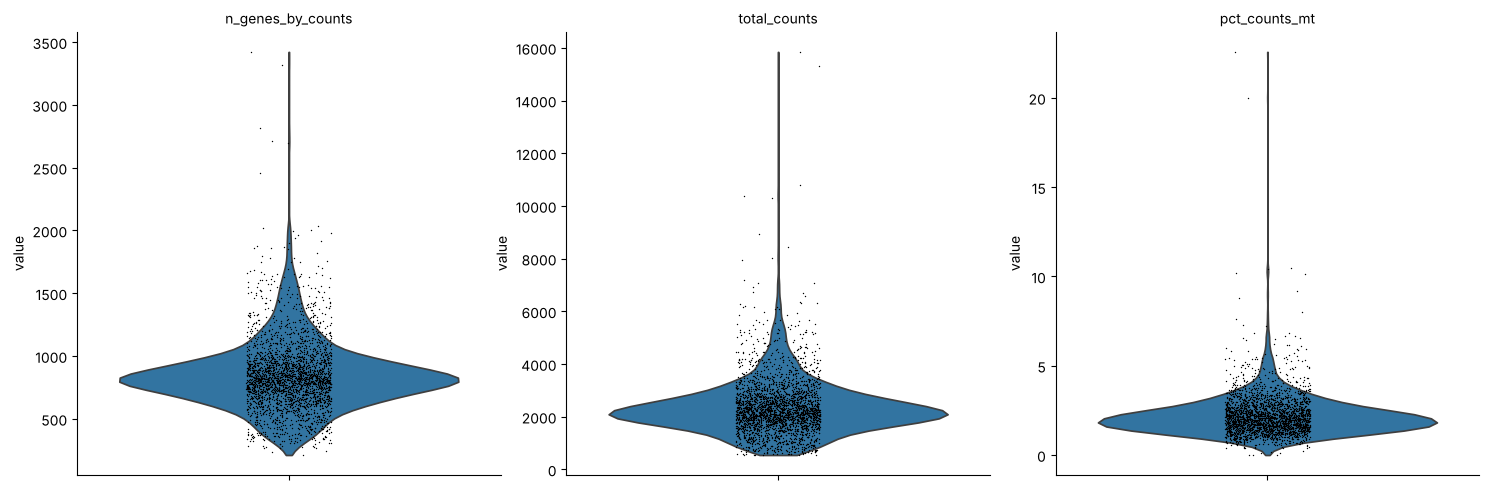

In [11]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [12]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [13]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [14]:
adata.layers["counts"] = adata.X.copy()

In [15]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

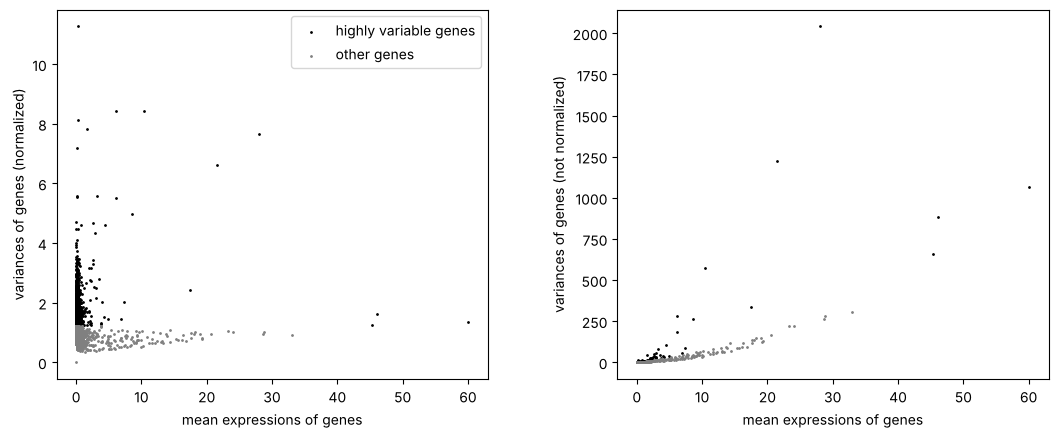

In [16]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [17]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

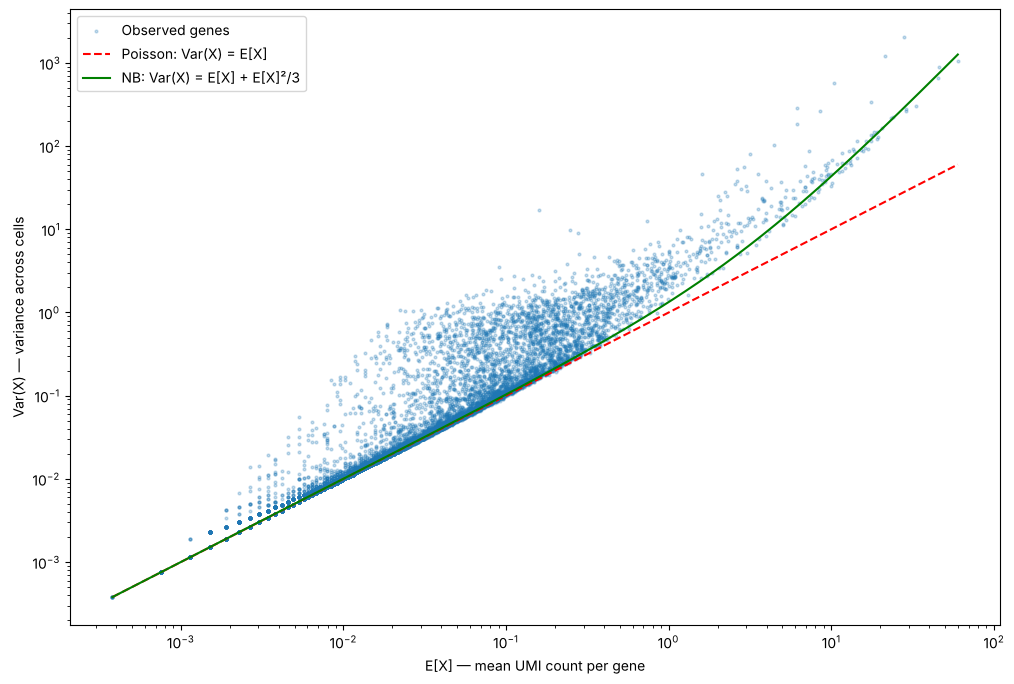

In [18]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [19]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

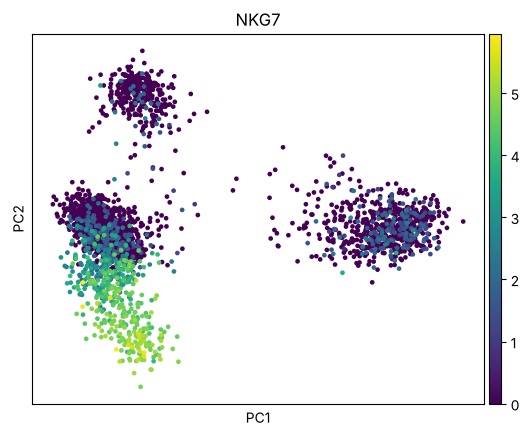

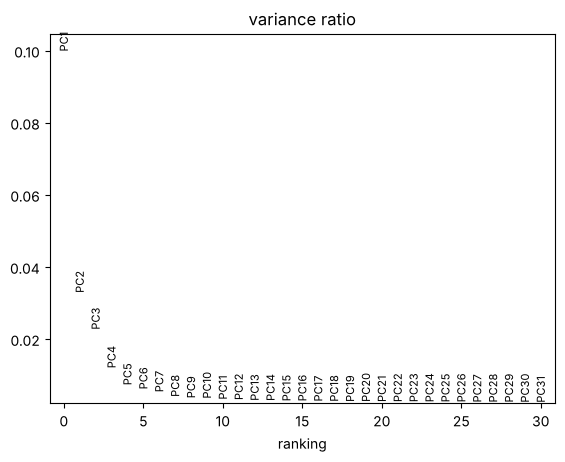

In [21]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [22]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте 

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Вспомогательные функции

`run_pipeline` повторяет шаги с занятия (QC-фильтрация → HVG `seurat_v3` → normalize → log1p → PCA), а флагами можно отключать отдельные шаги — это понадобится в заданиях 3, 5 и 7.

In [23]:
import pandas as pd

MARKERS = ["CD3D", "MS4A1", "NKG7", "LST1"]   # T, B, NK, моноциты


def load_raw():
    """Исходная матрица UMI counts + разметка групп генов + QC-метрики."""
    ad = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
    names = ad.var_names
    ad.var["mt"] = names.str.startswith("MT-")                  # митохондриальные
    ad.var["ribo"] = names.str.match(r"^RP[SL]")                # рибосомные белки
    ad.var["hb"] = names.str.match(r"^HB[ABDEGMQZ]\d*$")        # гемоглобины (без HBEGF, HBS1L и т.п.)
    sc.pp.calculate_qc_metrics(ad, qc_vars=["mt", "ribo", "hb"], percent_top=None, inplace=True)
    return ad


def run_pipeline(ad, qc_filter=True, use_hvg=True, normalize=True, log=True, scale=False):
    """Пайплайн с занятия; флагами отключаются отдельные шаги. Возвращает копию с PCA."""
    ad = ad.copy()
    if qc_filter:
        sc.pp.filter_cells(ad, min_genes=200)
        sc.pp.filter_genes(ad, min_cells=3)
        ad = ad[(ad.obs.n_genes_by_counts < 2500) & (ad.obs.pct_counts_mt < 5)].copy()
    else:
        # без QC: убираем только гены, у которых 0 UMI во всех клетках (они не несут информации)
        sc.pp.filter_genes(ad, min_counts=1)
    ad.layers["counts"] = ad.X.copy()
    if use_hvg:
        sc.pp.highly_variable_genes(ad, layer="counts", flavor="seurat_v3", n_top_genes=2000)
    if normalize:
        sc.pp.normalize_total(ad, target_sum=1e4)
    if log:
        sc.pp.log1p(ad)
    if scale:
        sc.pp.scale(ad)
    sc.tl.pca(ad, mask_var="highly_variable" if use_hvg else None, random_state=0)
    return ad


def pc_qc_corr(ad, metrics, n_pcs=2):
    """Корреляция Спирмена между координатами PC и QC-метриками клеток."""
    pcs = pd.DataFrame(ad.obsm["X_pca"][:, :n_pcs], index=ad.obs_names,
                       columns=[f"PC{i+1}" for i in range(n_pcs)])
    return pd.concat([pcs, ad.obs[metrics]], axis=1).corr(method="spearman").loc[metrics, pcs.columns].round(2)


adata_raw = load_raw()
print("Исходно клеток × генов:", adata_raw.shape)
print("После QC (основной adata с занятия):", adata.shape)

Исходно клеток × генов: (2700, 32738)
После QC (основной adata с занятия): (2638, 13714)


## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили. 

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


### Решение

Кроме митохондриальных генов (`MT-`), добавим две группы:
- **рибосомные белки** (`RPS*`, `RPL*`) — их доля отражает состояние клетки и качество библиотеки;
- **гемоглобины** (`HBA1`, `HBA2`, `HBB`, …) — маркер примеси эритроцитов / свободной РНК эритроцитов.

Метрики считаем на нефильтрованных данных: QC-графики нужны, чтобы выбрать пороги, поэтому на них должны быть видны и те клетки, которые фильтр потом уберёт. Красные линии — пороги с занятия.

In [24]:
print("Генов в группах:", {g: int(adata_raw.var[g].sum()) for g in ["mt", "ribo", "hb"]})
print("Гемоглобины:", list(adata_raw.var_names[adata_raw.var.hb]))

QC = ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"]
THR = {"n_genes_by_counts": [200, 2500], "pct_counts_mt": [5]}   # пороги с занятия

adata_raw.obs[QC].describe().round(2)

Генов в группах: {'mt': 13, 'ribo': 106, 'hb': 10}
Гемоглобины: ['HBB', 'HBD', 'HBG1', 'HBG2', 'HBE1', 'HBZ', 'HBM', 'HBA2', 'HBA1', 'HBQ1']


,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb
count,2700.00,2700.00,2700.00,2700.00,2700.00
mean,846.99,2366.90,2.22,34.95,0.00
std,282.10,1094.26,1.17,10.22,0.03
min,212.00,548.00,0.00,1.06,0.00
25%,690.00,1757.75,1.54,26.33,0.00
50%,817.00,2197.00,2.03,36.77,0.00
75%,953.25,2763.00,2.64,43.35,0.00
max,3422.00,15844.00,22.57,59.44,1.36


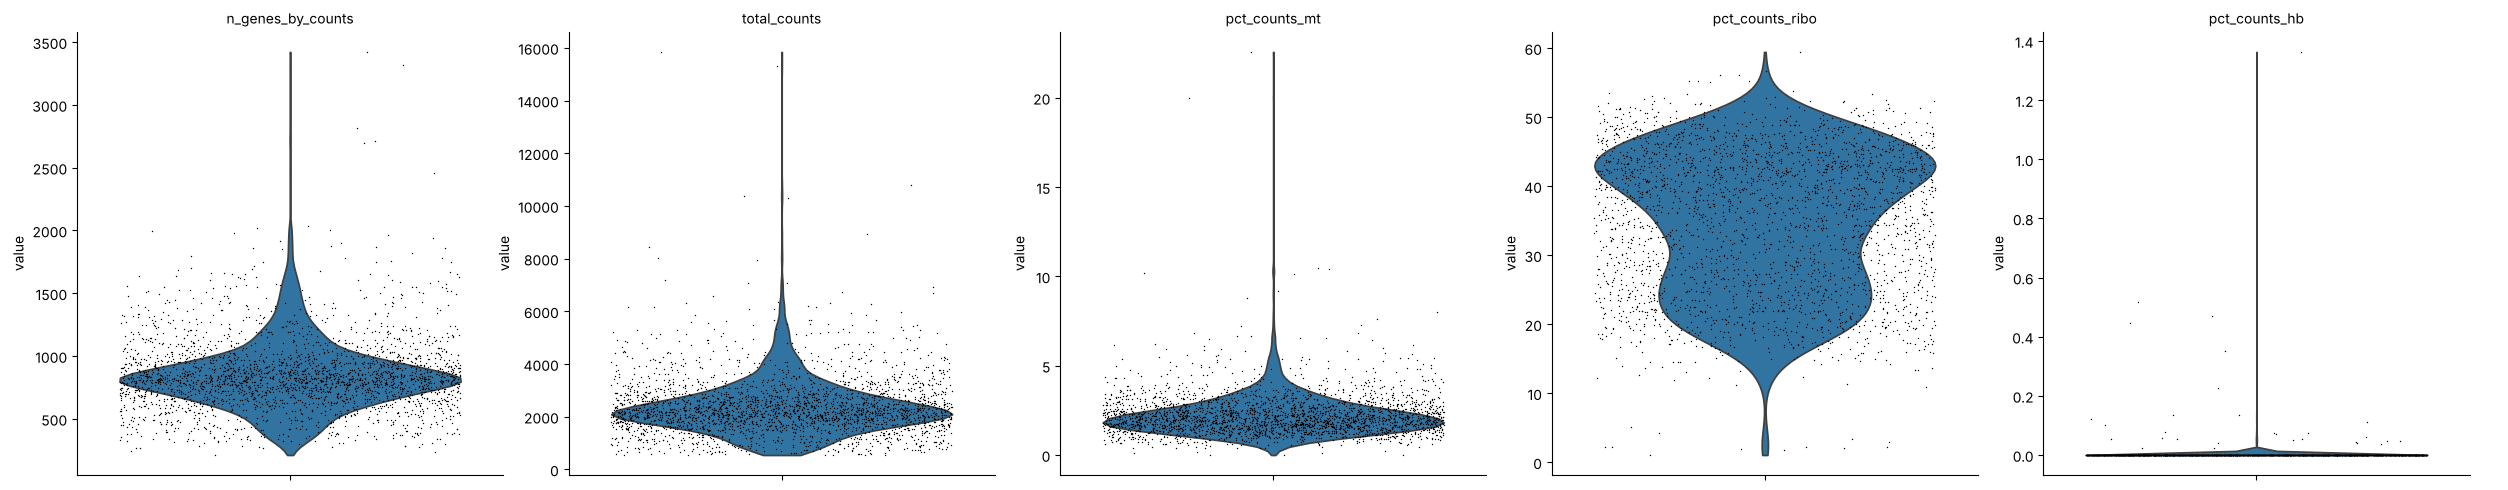

In [25]:
# 1. Violin plot
sc.pl.violin(adata_raw, QC, multi_panel=True, jitter=0.4, size=1)

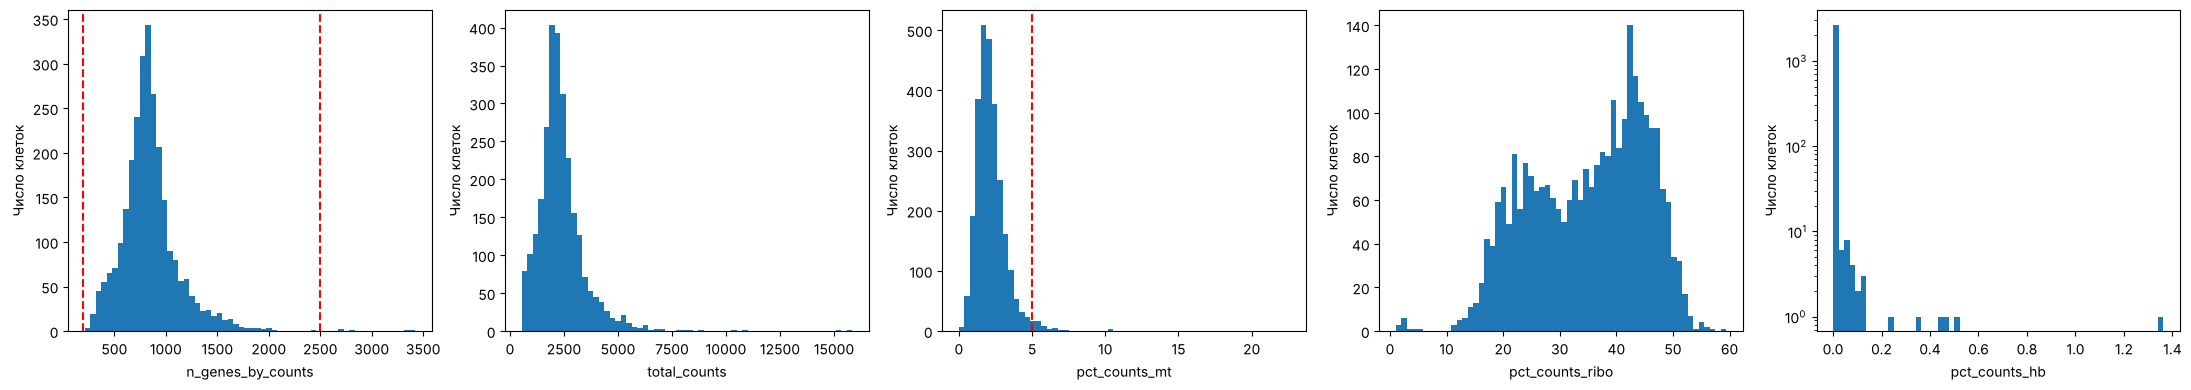

In [26]:
# 2. Гистограммы: X — значение метрики, Y — число клеток
fig, axes = plt.subplots(1, len(QC), figsize=(22, 4))
for ax, m in zip(axes, QC):
    ax.hist(adata_raw.obs[m], bins=60)
    for t in THR.get(m, []):
        ax.axvline(t, color="red", ls="--")
    ax.set(xlabel=m, ylabel="Число клеток")
axes[-1].set_yscale("log")   # почти у всех клеток доля Hb = 0, поэтому лог-шкала
plt.tight_layout(); plt.show()

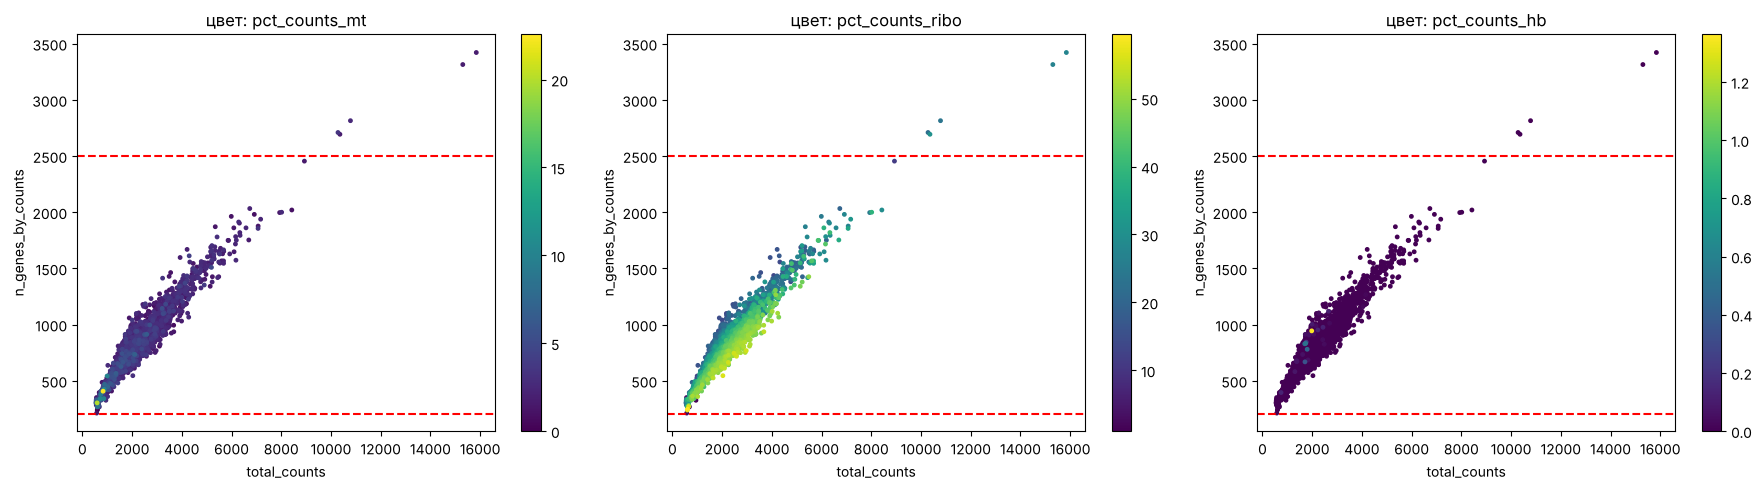

In [27]:
# 3. Scatter: число генов vs общее число UMI, цвет — доля каждой группы генов
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, m in zip(axes, ["pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"]):
    o = adata_raw.obs.sort_values(m)              # яркие точки рисуем поверх
    s = ax.scatter(o.total_counts, o.n_genes_by_counts, c=o[m], s=6, cmap="viridis")
    ax.axhline(2500, color="red", ls="--"); ax.axhline(200, color="red", ls="--")
    ax.set(xlabel="total_counts", ylabel="n_genes_by_counts", title=f"цвет: {m}")
    plt.colorbar(s, ax=ax)
plt.tight_layout(); plt.show()

In [28]:
# Сколько клеток выходит за пороги
obs = adata_raw.obs
flags = pd.Series({
    "n_genes < 200 (пустые/разрушенные)": (obs.n_genes_by_counts < 200).sum(),
    "n_genes > 2500 (кандидаты в дублеты)": (obs.n_genes_by_counts > 2500).sum(),
    "pct_mt > 5% (повреждённые)": (obs.pct_counts_mt > 5).sum(),
    "pct_hb > 1% (примесь эритроцитов)": (obs.pct_counts_hb > 1).sum(),
    "pct_ribo < 10%": (obs.pct_counts_ribo < 10).sum(),
}, name="клеток")
display(flags.to_frame())

# Связь доли рибосомных и митохондриальных UMI с глубиной
obs[["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]].corr("spearman").round(2)

,клеток
n_genes < 200 (пустые/разрушенные),0
n_genes > 2500 (кандидаты в дублеты),5
pct_mt > 5% (повреждённые),57
pct_hb > 1% (примесь эритроцитов),1
pct_ribo < 10%,12


,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo
total_counts,1.00,0.91,-0.11,0.04
n_genes_by_counts,0.91,1.00,-0.10,-0.23
pct_counts_mt,-0.11,-0.10,1.00,-0.21
pct_counts_ribo,0.04,-0.23,-0.21,1.00


In [29]:
# Кто такие клетки с очень низкой долей рибосомных UMI? Смотрим маркеры тромбоцитов PPBP и PF4
low_ribo = adata_raw[adata_raw.obs.pct_counts_ribo < 10]
pd.DataFrame(low_ribo[:, ["PPBP", "PF4"]].X.toarray(), index=low_ribo.obs_names, columns=["PPBP", "PF4"]) \
  .join(low_ribo.obs[["total_counts", "pct_counts_ribo"]].round(1))

,PPBP,PF4,total_counts,pct_counts_ribo
ACCCACTGGTTCAG-1,22.0,9.0,568.0,3.3
AGTCTTACTTCGGA-1,34.0,14.0,664.0,2.3
ATCATCTGACACCA-1,36.0,14.0,737.0,2.2
ATTCAGCTCATTGG-1,43.0,14.0,917.0,5.1
CGTACCTGGACGAG-1,0.0,0.0,833.0,4.2
GACGCTCTCTCTCG-1,66.0,9.0,683.0,2.2
GAGTTGTGGTAGCT-1,54.0,62.0,2422.0,1.8
GGAACACTTCAGAC-1,30.0,6.0,628.0,2.9
GGCATATGGGGAGT-1,41.0,11.0,575.0,2.3
GTCATACTTCGCCT-1,55.0,18.0,984.0,2.1


### Выводы

- **Предложенные группы генов.** Рибосомные белки (106 генов, `RPS*/RPL*`) и гемоглобины (10 генов). Доля рибосомных UMI в среднем ≈35 %, распределение **двугорбое** (пики около 22 % и 43 %). Доля гемоглобинов почти у всех клеток равна 0: эритроцитов в образце практически нет, только у 1 клетки она выше 1 %.
- **Подозрительные клетки:**
  - 5 клеток с `n_genes > 2500` и 10–16 тыс. UMI заметно отрываются от общего облака на scatter. Это вероятные **дублеты**: два транскриптома в одной капле;
  - 57 клеток с `pct_counts_mt > 5 %` (максимум 22.6 %). У них низкие `total_counts` и `n_genes` (левый нижний угол scatter). Это типичная картина **повреждённых клеток**: цитоплазматическая мРНК вытекла, а митохондриальная осталась;
  - клеток с `n_genes < 200` нет: Cell Ranger уже отбросил пустые капли.
- **Признаки низкого качества:** мало UMI и генов (пустая или разрушенная капля), высокая доля mt (повреждение мембраны), слишком много UMI и генов (дублет). Признак надёжнее, если он виден сразу по нескольким метрикам.
- **Почему высокая (или низкая) доля группы генов — не всегда брак.** Доля рибосомных UMI зависит от типа клетки: два горба гистограммы соответствуют лимфоцитам (высокая доля) и моноцитам (низкая). 11 из 12 клеток с долей рибосомных UMI < 10 % оказались **тромбоцитами**: в них высоко экспрессированы `PPBP` и `PF4`. Это реальная популяция, а не брак. Аналогично, высокая доля mt бывает у метаболически активных клеток (кардиомиоциты, гепатоциты), а высокая доля Hb — у эритроидных клеток. Поэтому пороги выбирают для конкретной ткани, а не переносят механически.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`. 

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


### Решение

- `seurat_v3` — уже посчитан на занятии (работает с сырыми counts);
- `seurat` — работает с **лог-нормализованными** данными, т.е. с текущим `adata.X`;
- `sc.experimental.pp.highly_variable_genes` — метод Pearson residuals, работает с сырыми counts (`layer="counts"`).

Во всех трёх методах берём 2000 генов. PCA во всех случаях строится по одной и той же матрице `adata.X` (normalize + log1p), отличается только набор генов (`mask_var`).

In [30]:
adata.var["hvg_seurat_v3"] = adata.var["highly_variable"]

hvg_seurat = sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000, inplace=False)
adata.var["hvg_seurat"] = hvg_seurat["highly_variable"].values

hvg_pearson = sc.experimental.pp.highly_variable_genes(
    adata, flavor="pearson_residuals", n_top_genes=2000, layer="counts", inplace=False)
adata.var["hvg_pearson"] = hvg_pearson["highly_variable"].values

METHODS = ["hvg_seurat_v3", "hvg_seurat", "hvg_pearson"]
for m in METHODS:
    sc.tl.pca(adata, mask_var=m, key_added=f"pca_{m}", random_state=0)
    print(m, "— генов:", adata.var[m].sum())

hvg_seurat_v3 — генов: 2000


hvg_seurat — генов: 2000


hvg_pearson — генов: 2000


In [31]:
# Пересечения наборов HVG
sets = {m: set(adata.var_names[adata.var[m]]) for m in METHODS}
overlap = pd.DataFrame({a: {b: len(sets[a] & sets[b]) for b in METHODS} for a in METHODS})
display(overlap)
print("Во всех трёх наборах одновременно:", len(set.intersection(*sets.values())))

,hvg_seurat_v3,hvg_seurat,hvg_pearson
hvg_seurat_v3,2000,1505,1402
hvg_seurat,1505,2000,1291
hvg_pearson,1402,1291,2000


Во всех трёх наборах одновременно: 1145


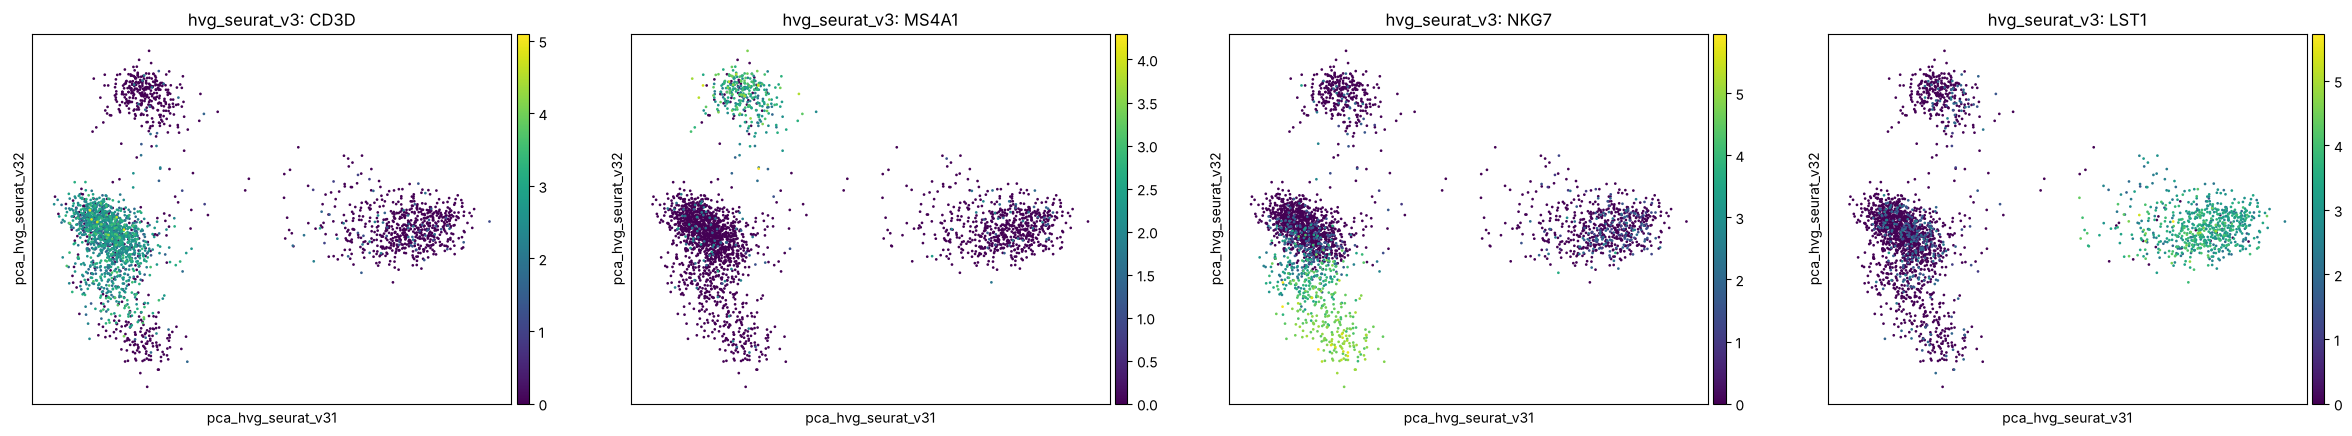

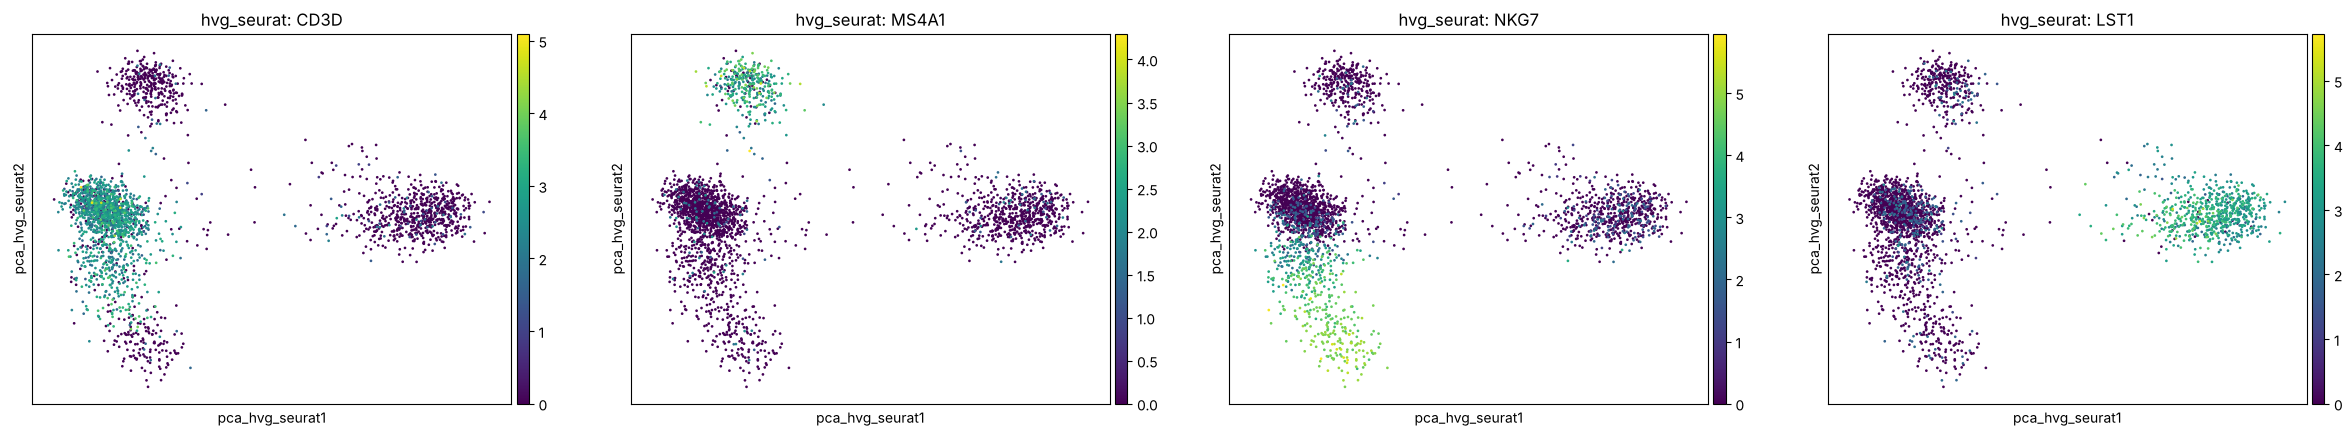

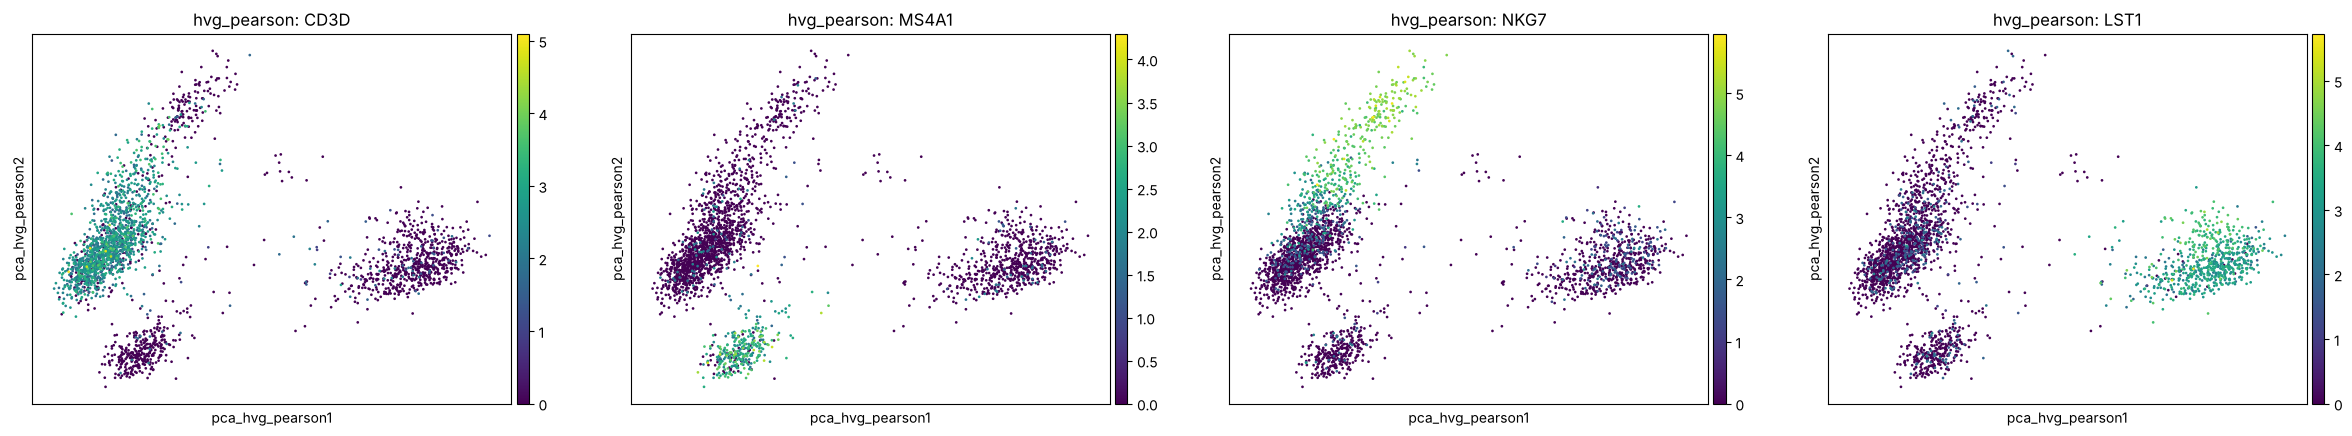

In [32]:
# PCA по каждому набору HVG, окраска по маркерам
for m in METHODS:
    sc.pl.embedding(adata, basis=f"pca_{m}", color=MARKERS, ncols=4, size=15,
                    title=[f"{m}: {g}" for g in MARKERS])

In [33]:
# Количественно: насколько совпадают первые компоненты (|corr|, знак PC произволен)
pcs = {m: adata.obsm[f"pca_{m}"][:, :2] for m in METHODS}
rows = []
for i, a in enumerate(METHODS):
    for b in METHODS[i + 1:]:
        rows.append({"пара": f"{a} vs {b}",
                     "|corr| PC1": abs(np.corrcoef(pcs[a][:, 0], pcs[b][:, 0])[0, 1]),
                     "|corr| PC2": abs(np.corrcoef(pcs[a][:, 1], pcs[b][:, 1])[0, 1])})
pd.DataFrame(rows).round(3)

,пара,|corr| PC1,|corr| PC2
0,hvg_seurat_v3 vs hvg_seurat,0.997,0.991
1,hvg_seurat_v3 vs hvg_pearson,0.990,0.928
2,hvg_seurat vs hvg_pearson,0.990,0.944


### Выводы

- **Пересечение наборов** (по 2000 генов в каждом): `seurat_v3` ∩ `seurat` = 1505, `seurat_v3` ∩ Pearson residuals = 1402, `seurat` ∩ Pearson = 1291. Во всех трёх наборах одновременно — **1145 генов**. Значит, методы согласны примерно на 2/3, а остальная треть генов у каждого метода своя.
- **Расположение клеток почти одинаковое.** |corr| PC1 между методами 0.99–0.997, PC2 — 0.93–0.99. Различаются в основном зеркальные отражения осей (знак PC произволен) и небольшие сдвиги.
- **Группы по маркерам сохраняются во всех трёх PCA:** моноциты `LST1` отделяются по PC1, B-клетки `MS4A1` отдельная группа, `CD3D` (T) и `NKG7` (NK) — соседние части большого лимфоидного облака.
- **Вывод:** главная структура данных (миелоидные / B / T / NK) устойчива к выбору метода HVG. Различия касаются генов «второго плана», которые слабее влияют на первые компоненты.

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


### Решение

Тот же пайплайн (QC, normalize, log1p), но PCA по всем генам, прошедшим QC.

Генов в PCA: HVG = 2000 | все гены = 13714


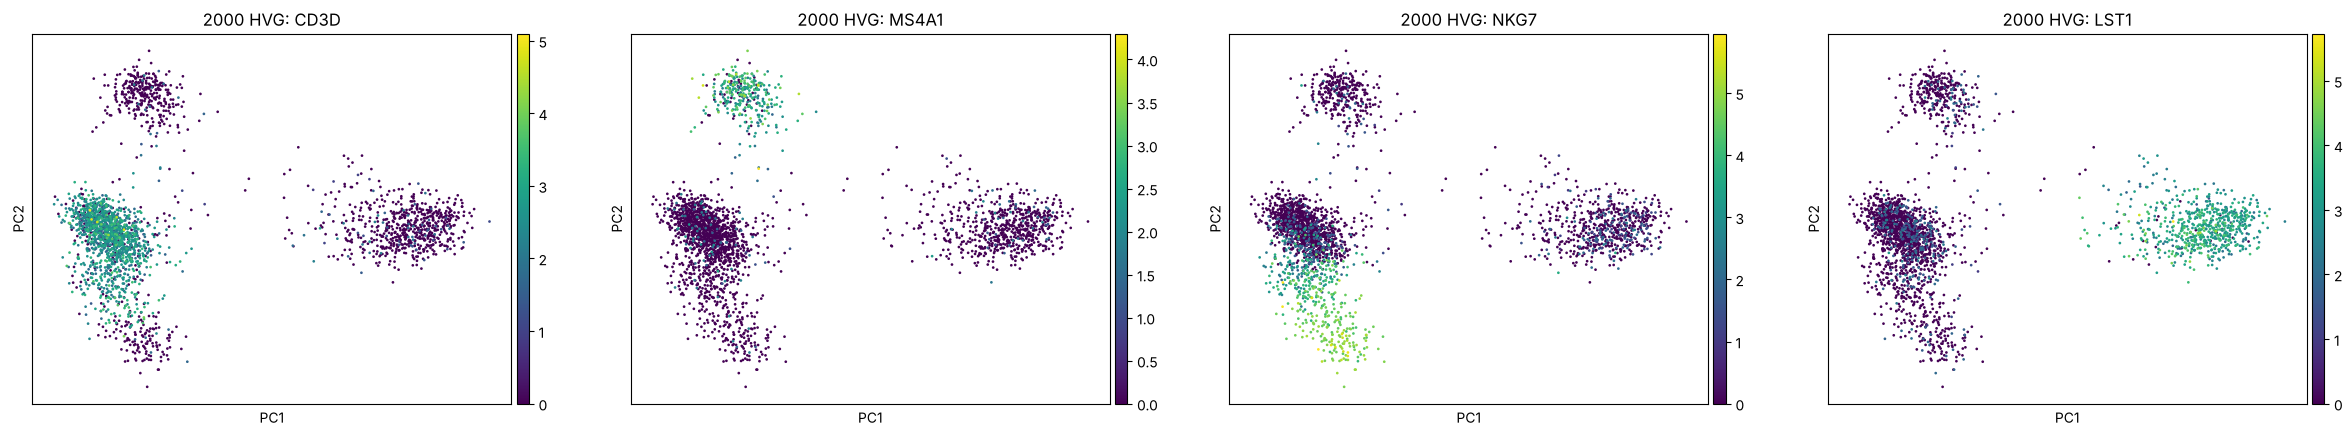

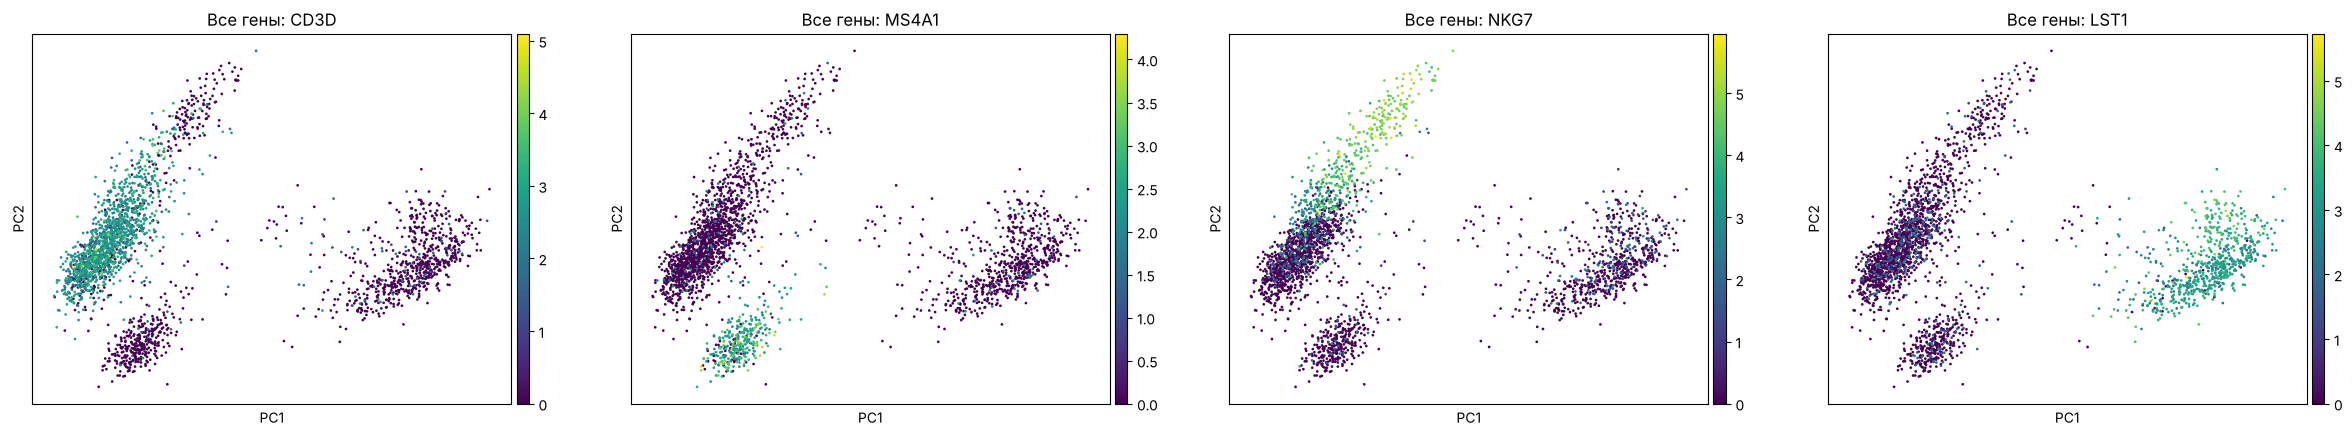

In [34]:
adata_hvg = run_pipeline(adata_raw, use_hvg=True)
adata_all = run_pipeline(adata_raw, use_hvg=False)
print("Генов в PCA: HVG =", adata_hvg.var.highly_variable.sum(), "| все гены =", adata_all.n_vars)

sc.pl.pca(adata_hvg, color=MARKERS, ncols=4, size=15, title=[f"2000 HVG: {g}" for g in MARKERS])
sc.pl.pca(adata_all, color=MARKERS, ncols=4, size=15, title=[f"Все гены: {g}" for g in MARKERS])

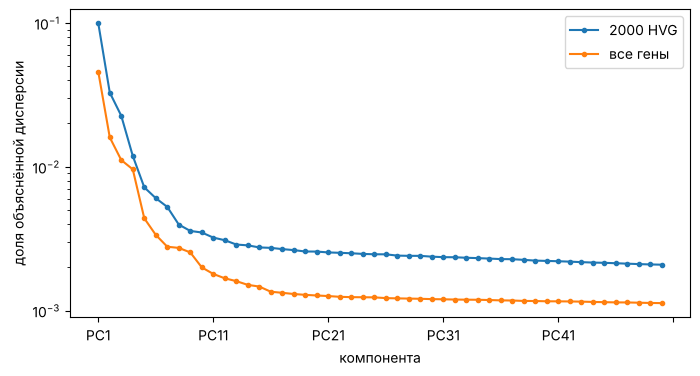

,2000 HVG,все гены
PC1,0.0998,0.0458
PC2,0.0328,0.0160
PC3,0.0226,0.0111
PC4,0.0119,0.0096
PC5,0.0072,0.0044


Суммарно первые 10 PC:
 2000 HVG    0.197
все гены    0.100
dtype: float32


In [35]:
# Доля объяснённой дисперсии
vr = pd.DataFrame({"2000 HVG": adata_hvg.uns["pca"]["variance_ratio"],
                   "все гены": adata_all.uns["pca"]["variance_ratio"]},
                  index=[f"PC{i+1}" for i in range(50)])

fig, ax = plt.subplots(figsize=(8, 4))
vr.plot(ax=ax, marker="o", ms=3)
ax.set(xlabel="компонента", ylabel="доля объяснённой дисперсии", yscale="log")
plt.show()

display(vr.head(5).round(4))
print("Суммарно первые 10 PC:\n", vr.head(10).sum().round(3))

### Выводы

- **Структура клеток почти не изменилась:** на PC1–PC2 видны те же группы (моноциты `LST1`, B-клетки `MS4A1`, T/NK `CD3D`/`NKG7`).
- **Больше дисперсии объясняют компоненты PCA по HVG.** PC1: 10.0 % на HVG против 4.6 % на всех генах; первые 10 PC: 19.7 % против 10.0 %. По всем 13 714 генам картинка такая же, но доля дисперсии в первых PC вдвое меньше.
- **Почему все гены не делают PCA информативнее.** Большинство генов в отдельной клетке экспрессируются слабо: их вариация — в основном пуассоновский шум отбора UMI, а не биология. Эти тысячи генов добавляют в общую дисперсию шум, и доля сигнала в первых компонентах падает. Сигнал о типах клеток сосредоточен в нескольких сотнях вариабельных генов, а отбор HVG по сути работает как фильтр шума (и заодно ускоряет вычисления).

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


### Решение

Среднее и дисперсию считаем по исходным counts (`adata.layers["counts"]`). Дополнительно смотрим `variances_norm` — именно по этой величине `seurat_v3` ранжирует гены: дисперсия после стандартизации относительно ожидаемой при данном среднем.

In [36]:
def gene_group(g):
    """Грубая функциональная группа гена по названию."""
    if g.startswith("MT-"):            return "митохондриальный"
    if g.startswith(("RPL", "RPS")):  return "рибосомный белок"
    if g.startswith("HLA-") or g in {"CD74", "B2M"}: return "MHC / презентация антигена"
    return "другое"

X = adata.layers["counts"]
mean = np.asarray(X.mean(axis=0)).ravel()
var = np.asarray(X.power(2).mean(axis=0)).ravel() - mean**2

genes = pd.DataFrame({"mean_UMI": mean, "variance": var,
                      "var/mean": var / np.where(mean > 0, mean, np.nan),
                      "variances_norm": adata.var["variances_norm"].values,
                      "HVG": adata.var["highly_variable"].values},
                     index=adata.var_names)
genes["группа"] = [gene_group(g) for g in genes.index]

top_hvg = genes[genes.HVG].nlargest(50, "mean_UMI")
top_non = genes[~genes.HVG].nlargest(50, "mean_UMI")

summary = pd.DataFrame({"HVG (топ-50)": top_hvg[["mean_UMI", "variance", "var/mean", "variances_norm"]].median(),
                        "не HVG (топ-50)": top_non[["mean_UMI", "variance", "var/mean", "variances_norm"]].median()})
display(summary.round(2).rename_axis("медиана"))
display(pd.DataFrame({"HVG": top_hvg["группа"].value_counts(), "не HVG": top_non["группа"].value_counts()}).fillna(0).astype(int))

top50_all = genes.nlargest(50, "mean_UMI")
print(f"Из 50 самых экспрессируемых генов вообще HVG только {top50_all.HVG.sum()}")

,HVG (топ-50),не HVG (топ-50)
медиана,,
mean_UMI,2.63,12.93
variance,29.46,67.72
var/mean,10.31,5.72
variances_norm,2.02,0.80


,HVG,не HVG
группа,,
MHC / презентация антигена,6,0
другое,43,4
митохондриальный,1,1
рибосомный белок,0,45


Из 50 самых экспрессируемых генов вообще HVG только 7


In [37]:
pd.set_option("display.max_rows", 60)
print("Топ-50 HVG по среднему числу UMI")
display(top_hvg.drop(columns="HVG").round(2))

Топ-50 HVG по среднему числу UMI


,mean_UMI,variance,var/mean,variances_norm,группа
MALAT1,60.040001,1066.569946,17.770000,1.35,другое
TMSB4X,46.139999,883.349976,19.139999,1.64,другое
B2M,45.290001,659.150024,14.550000,1.25,MHC / презентация антигена
FTL,28.000000,2041.890015,72.930000,7.67,другое
FTH1,21.540001,1224.520020,56.860001,6.64,другое
ACTB,17.459999,334.399994,19.150000,2.42,другое
LYZ,10.410000,575.140015,55.259998,8.43,другое
CD74,8.580000,261.790009,30.510000,4.97,MHC / презентация антигена
S100A4,7.340000,86.239998,11.740000,2.02,другое
MT-CO2,6.890000,56.959999,8.270000,1.45,митохондриальный


In [38]:
print("Топ-50 НЕ-HVG по среднему числу UMI")
display(top_non.drop(columns="HVG").round(2))

Топ-50 НЕ-HVG по среднему числу UMI


,mean_UMI,variance,var/mean,variances_norm,группа
RPL10,33.020000,307.450012,9.31,0.92,рибосомный белок
RPL13,28.770000,280.540009,9.75,1.01,рибосомный белок
RPL13A,28.639999,264.609985,9.24,0.96,рибосомный белок
RPS2,24.090000,222.750000,9.25,1.03,рибосомный белок
RPS6,23.290001,217.960007,9.36,1.06,рибосомный белок
RPS18,20.610001,166.669998,8.09,0.96,рибосомный белок
RPL11,19.290001,128.380005,6.66,0.81,рибосомный белок
RPL32,19.240000,122.029999,6.34,0.77,рибосомный белок
RPS3,19.010000,146.750000,7.72,0.94,рибосомный белок
RPL19,18.270000,149.699997,8.19,1.02,рибосомный белок


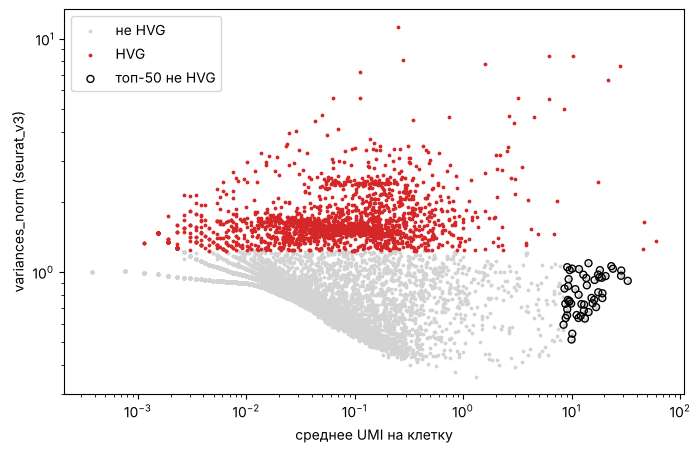

In [39]:
# Все гены: среднее vs нормированная дисперсия
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(genes.mean_UMI[~genes.HVG], genes.variances_norm[~genes.HVG], s=3, c="lightgrey", label="не HVG")
ax.scatter(genes.mean_UMI[genes.HVG], genes.variances_norm[genes.HVG], s=3, c="tab:red", label="HVG")
ax.scatter(top_non.mean_UMI, top_non.variances_norm, s=25, facecolors="none", edgecolors="k", label="топ-50 не HVG")
ax.set(xscale="log", yscale="log", xlabel="среднее UMI на клетку", ylabel="variances_norm (seurat_v3)")
ax.legend(); plt.show()

### Выводы

- **HVG не обязательно самые экспрессируемые гены.** Среди 50 самых экспрессируемых генов вообще HVG только 7. Медиана среднего числа UMI у топ-50 не-HVG — 12.9, у топ-50 HVG — 2.6.
- **Не-HVG гены имеют большую абсолютную дисперсию** (медиана 68 против 29), но **нормированная дисперсия** у них ниже: `variances_norm` 0.8 против 2.0, var/mean 5.7 против 10.3. `seurat_v3` сравнивает дисперсию с ожидаемой для гена с таким же средним, а не саму дисперсию.
- **Почему высоко экспрессированный ген может не попасть в HVG.** Ген может экспрессироваться ровно во всех клетках, и тогда его разброс объясняется средним уровнем и техническим шумом. Это видно по составу не-HVG: **45 из 50 — рибосомные белки** (`RPL10`, `RPL13`, `RPS2`…), а также `EEF1A1`, `TPT1`, `TMSB10`, `MT-CO1`. Это гены «домашнего хозяйства»: трансляция и энергетика нужны любой клетке.
- **Высоко экспрессированные HVG** — гены, уровень которых зависит от типа клетки:
  - моноцитарные: `LYZ`, `S100A8/9`, `CST3`, `FCN1`, `LST1`, `AIF1`;
  - MHC II (антигенпрезентирующие клетки): `HLA-DRA`, `CD74`, `HLA-DP*`;
  - NK и цитотоксические: `NKG7`, `GNLY`, `CCL5`;
  - T-клеточные: `LTB`, `IL32`;
  - ферритины `FTL/FTH1` (высоко в моноцитах).
- **Вывод:** HVG отбирают гены с *избыточной* относительно шума вариабельностью, то есть различающие популяции, а не самые «громкие».

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

### Решение

Строим 4 варианта пайплайна и красим PCA по QC-метрикам. Для количественной проверки дополнительно считаем корреляцию Спирмена PC1/PC2 с метриками.

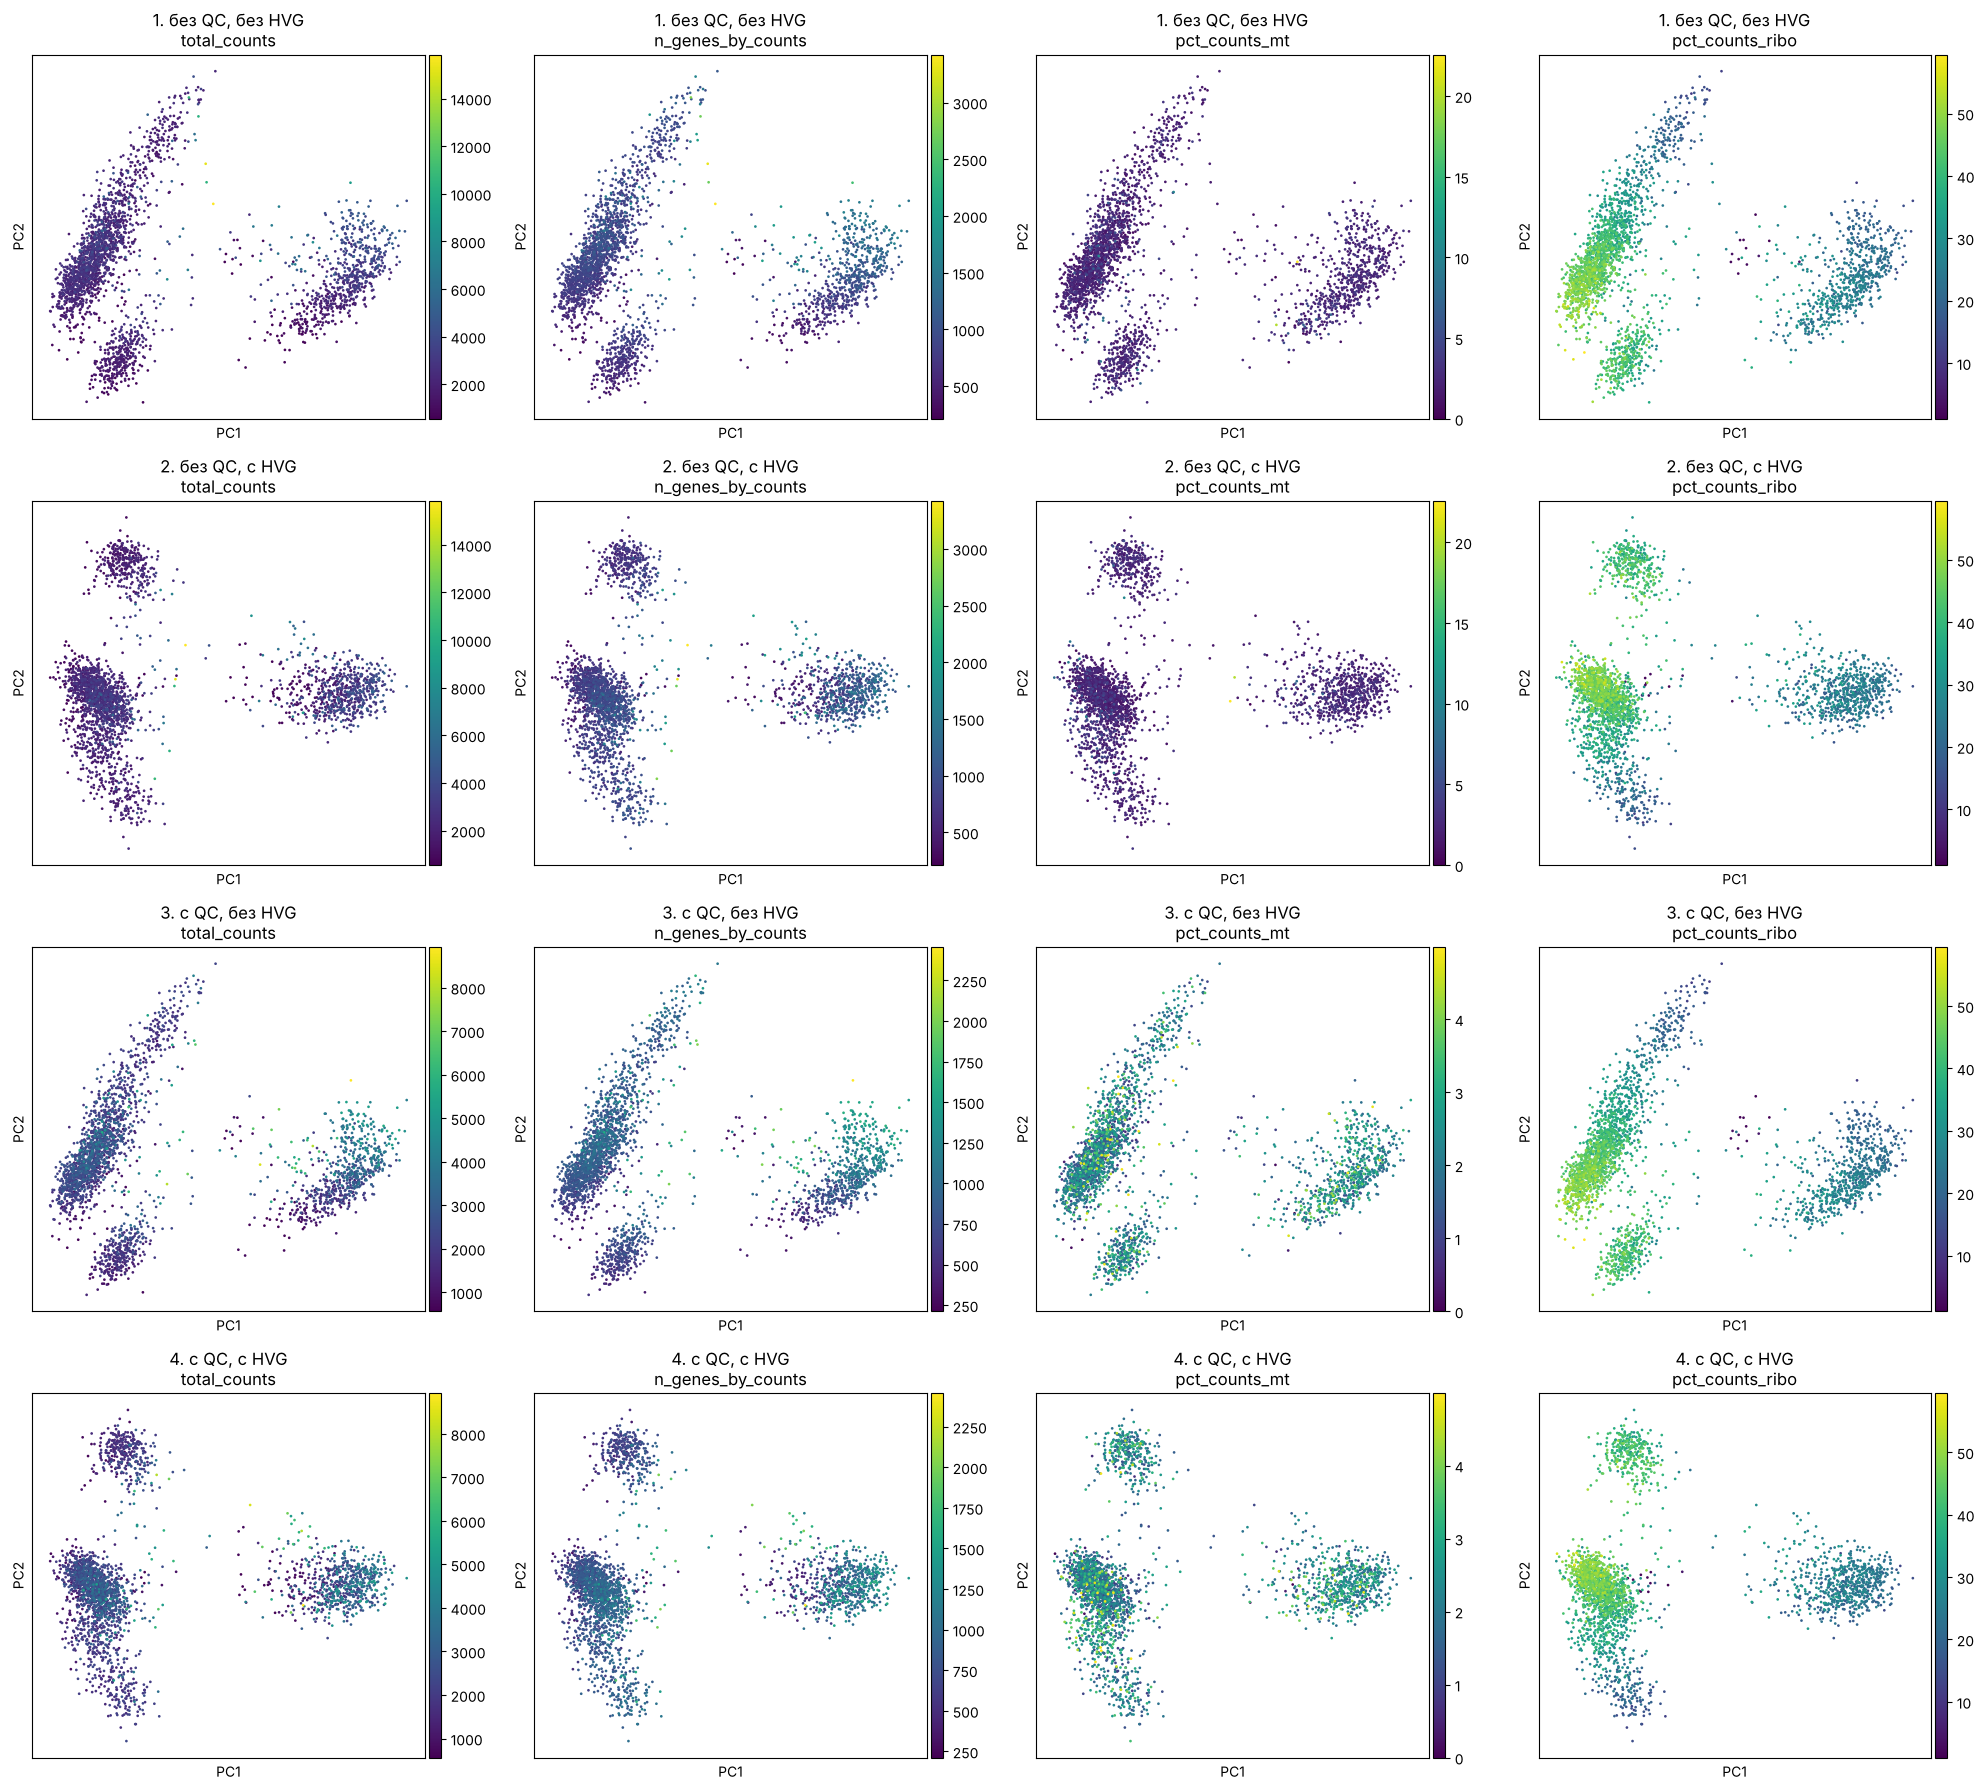

In [40]:
QC5 = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
cases = {
    "1. без QC, без HVG": run_pipeline(adata_raw, qc_filter=False, use_hvg=False),
    "2. без QC, с HVG":   run_pipeline(adata_raw, qc_filter=False, use_hvg=True),
    "3. с QC, без HVG":   run_pipeline(adata_raw, qc_filter=True,  use_hvg=False),
    "4. с QC, с HVG":     run_pipeline(adata_raw, qc_filter=True,  use_hvg=True),
}

fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for row, (name, ad) in zip(axes, cases.items()):
    for ax, m in zip(row, QC5):
        sc.pl.pca(ad, color=m, ax=ax, show=False, size=15, title=f"{name}\n{m}")
plt.tight_layout(); plt.show()

In [41]:
# Корреляции Спирмена PC1/PC2 с QC-метриками для каждого варианта
pd.concat({name: pc_qc_corr(ad, QC5) for name, ad in cases.items()}, axis=1)

1. без QC, без HVG       2. без QC, с HVG        \
                                 PC1   PC2              PC1   PC2   
total_counts                    0.15  0.35             0.27 -0.08   
n_genes_by_counts               0.34  0.55             0.38 -0.27   
pct_counts_mt                   0.16 -0.05             0.09 -0.04   
pct_counts_ribo                -0.83 -0.33            -0.66  0.32   

                  3. с QC, без HVG       4. с QC, с HVG        
                               PC1   PC2            PC1   PC2  
total_counts                  0.15  0.30           0.24 -0.07  
n_genes_by_counts             0.34  0.51           0.36 -0.26  
pct_counts_mt                 0.17 -0.03           0.13 -0.04  
pct_counts_ribo              -0.83 -0.35          -0.68  0.34

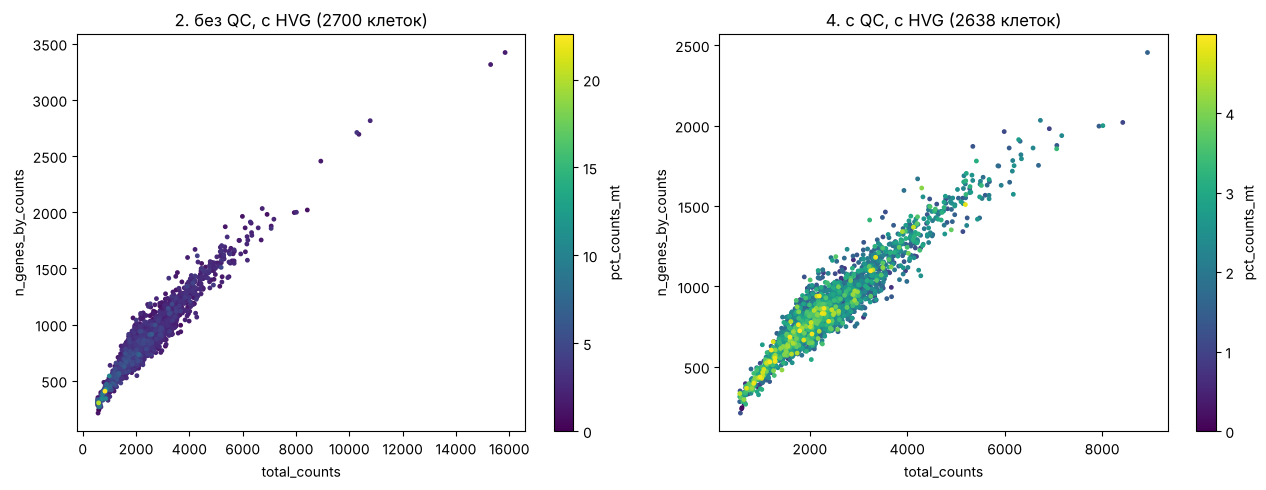

In [42]:
# Scatter: total_counts vs n_genes_by_counts, цвет — pct_counts_mt (без QC и после QC)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["2. без QC, с HVG", "4. с QC, с HVG"]):
    o = cases[name].obs.sort_values("pct_counts_mt")
    s = ax.scatter(o.total_counts, o.n_genes_by_counts, c=o.pct_counts_mt, s=6, cmap="viridis")
    ax.set(xlabel="total_counts", ylabel="n_genes_by_counts", title=f"{name} ({len(o)} клеток)")
    plt.colorbar(s, ax=ax, label="pct_counts_mt")
plt.tight_layout(); plt.show()

Повтор анализа «без фильтрации и QC, но с HVG» — это вариант 2 выше (вторая строка графиков, второй столбец таблицы корреляций и левый scatter).

### Выводы

- **Связь с числом UMI есть, но умеренная, и в основном через биологию.** Во всех вариантах |ρ| между PC1/PC2 и `total_counts`/`n_genes` не больше 0.55. На графиках видно, что глубина различается между *кластерами*: у моноцитов (правое облако) больше UMI и генов, чем у лимфоцитов. Плавного градиента глубины внутри одного кластера нет.
- **Митохондриальная доля** почти не связана с PC1/PC2 (|ρ| ≤ 0.17). Без QC клетки с высокой mt разбросаны по всем группам, отдельного направления они не образуют: при 57 таких клетках из 2700 их вклад в первые PC мал.
- **Сильнее всего с PC1 связана доля рибосомных UMI:** ρ = −0.83 без HVG и −0.66…−0.68 с HVG. Но это не технический артефакт: PC1 разделяет лимфоциты (много рибосомных транскриптов) и моноциты (мало), то есть рибосомная доля здесь отражает тип клетки.
- **QC-фильтрация на PC1–PC2 почти не влияет:** варианты 1 ↔ 3 и 2 ↔ 4 выглядят одинаково, корреляции отличаются на 0.01–0.04. Сильнее меняет картину **отбор HVG**: без HVG PC2 сильнее связана с числом генов (ρ = 0.51–0.55 против −0.26…−0.27) и форма облаков другая.
- **Можно ли заподозрить технические факторы?** Подозревать можно и нужно: корреляции PC с `total_counts`, `n_genes` и долей рибосомных UMI ненулевые. Но по графикам видно, что эти метрики меняются *между* биологическими популяциями. Для PBMC 3k главные компоненты определяет биология, а сильного технического направления нет. В вариантах без QC scatter показывает выбросы (дублеты справа сверху, повреждённые клетки с высокой mt в левом нижнем углу), но на первых двух PC они не выделяются: их слишком мало.


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

### Решение

Loadings лежат в `adata.varm["PCs"]` (для генов вне HVG они равны 0).

PC1 +: ['LYZ', 'CST3', 'S100A9', 'TYROBP', 'S100A8', 'LGALS1', 'AIF1', 'LST1', 'FCER1G', 'FCN1']
PC1 −: ['LTB', 'IL32', 'MALAT1', 'IL7R', 'CCL5', 'CD2', 'CTSW', 'STK17A', 'ACAP1', 'CD247']
PC2 +: ['HLA-DRA', 'CD74', 'HLA-DPB1', 'HLA-DRB1', 'CD79A', 'HLA-DPA1', 'HLA-DQA1', 'HLA-DQB1', 'CD79B', 'HLA-DRB5']
PC2 −: ['NKG7', 'S100A4', 'CCL5', 'IL32', 'GNLY', 'CTSW', 'GZMA', 'CST7', 'SRGN', 'ANXA1']


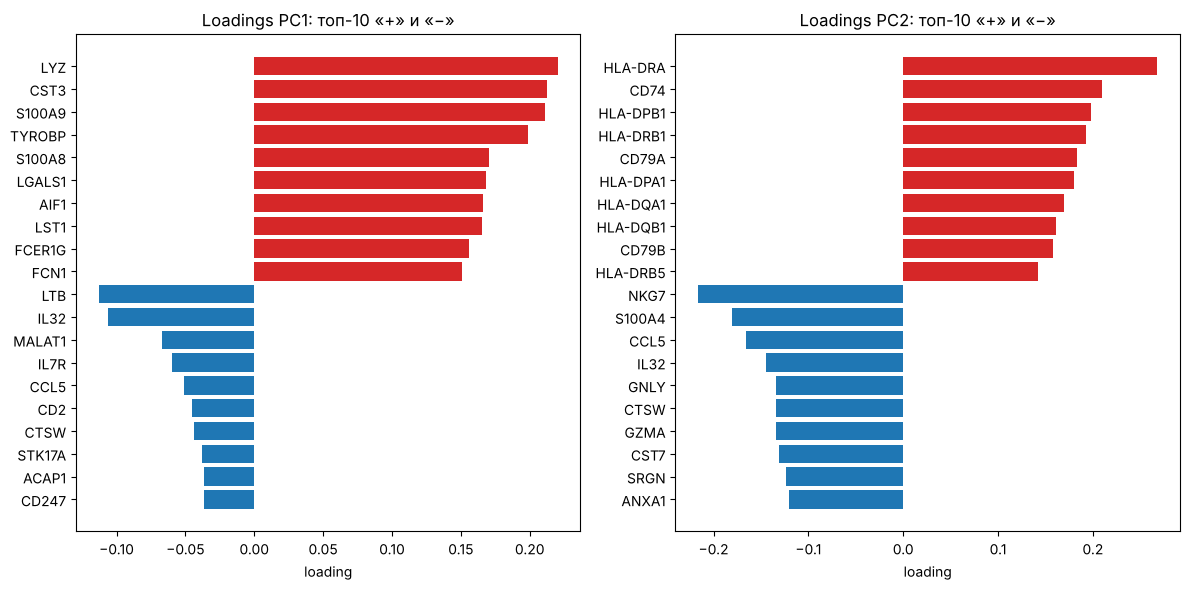

In [43]:
loadings = pd.DataFrame(adata.varm["PCs"][:, :2], index=adata.var_names, columns=["PC1", "PC2"])
loadings = loadings[adata.var["highly_variable"]]

top = {}
for pc in ["PC1", "PC2"]:
    s = loadings[pc].sort_values()
    top[pc] = pd.concat([s.tail(10)[::-1], s.head(10)])   # 10 положительных + 10 отрицательных
    print(f"{pc} +:", list(s.tail(10)[::-1].index))
    print(f"{pc} −:", list(s.head(10).index))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    s = top[pc][::-1]
    ax.barh(s.index, s.values, color=np.where(s > 0, "tab:red", "tab:blue"))
    ax.set(title=f"Loadings {pc}: топ-10 «+» и «−»", xlabel="loading")
plt.tight_layout(); plt.show()

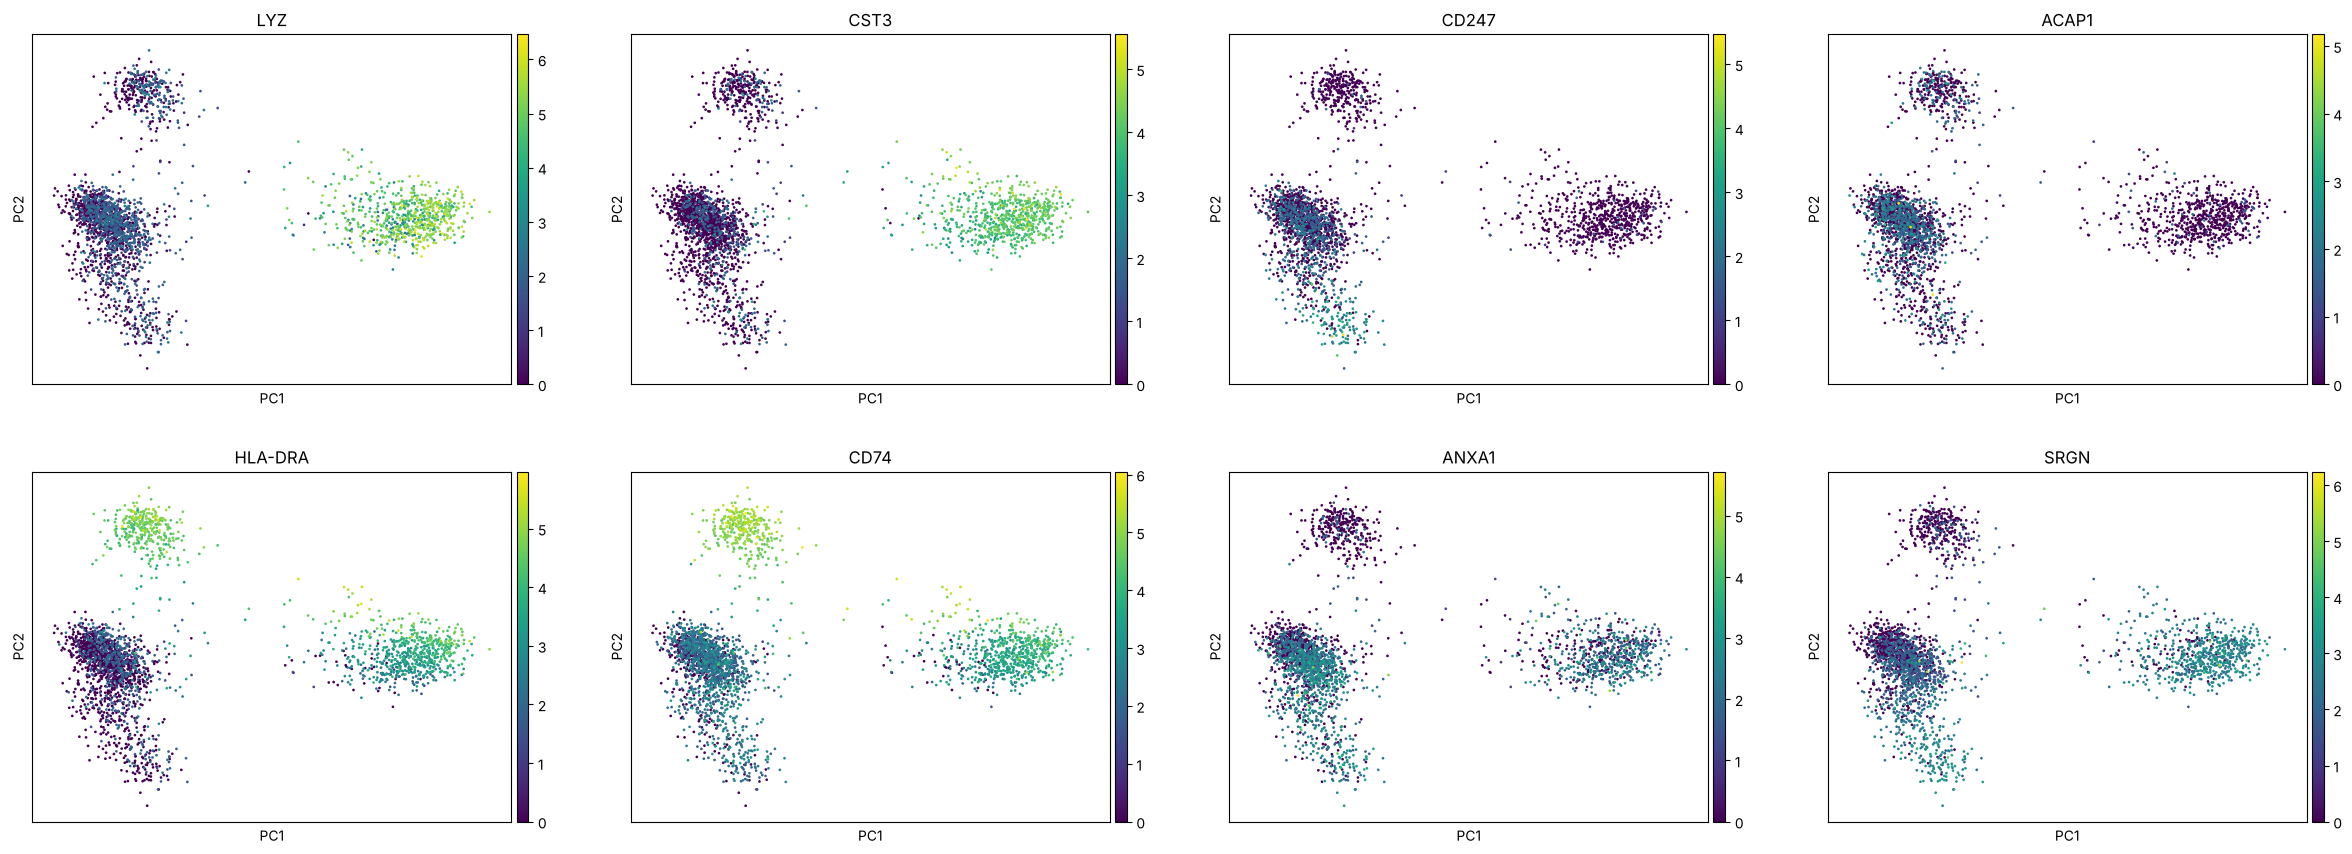

In [44]:
# Экспрессия нескольких найденных генов на PCA: по 2 самых «+» и «−» гена для каждой PC
genes6 = list(top["PC1"].index[[0, 1, -1, -2]]) + list(top["PC2"].index[[0, 1, -1, -2]])
sc.pl.pca(adata, color=genes6, ncols=4, size=15)

In [45]:
# Связаны ли PC1/PC2 с QC-метриками?
pc_qc_corr(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt"])

,PC1,PC2
total_counts,0.24,-0.07
n_genes_by_counts,0.36,-0.26
pct_counts_mt,0.13,-0.04


### Выводы

- **PC1 — ось «миелоидные ↔ лимфоидные клетки».**
  - «+»: `LYZ`, `CST3`, `S100A9`, `S100A8`, `TYROBP`, `LGALS1`, `AIF1`, `LST1`, `FCER1G`, `FCN1` — гены моноцитов;
  - «−»: `LTB`, `IL32`, `IL7R`, `CD2`, `CD247`, `CCL5`, `CTSW` — гены T-клеток (и частично NK), а также `MALAT1`.
- **PC2 — ось «B-клетки / антигенпрезентация ↔ цитотоксические клетки».**
  - «+»: `HLA-DRA`, `CD74`, `HLA-DPB1`, `HLA-DRB1`, `HLA-DQA1/DQB1`, `CD79A`, `CD79B` — MHC II и B-клеточный рецептор;
  - «−»: `NKG7`, `GNLY`, `GZMA`, `CST7`, `CCL5`, `CTSW` — гранзимы и перфориновый путь NK и CD8 T-клеток.
- **Связь с клеточным циклом и QC.** Генов клеточного цикла среди топ-loadings нет. С QC-метриками PC1/PC2 связаны слабо (|ρ| ≤ 0.36), и эта связь объясняется разной глубиной у моноцитов и лимфоцитов (см. задание 5).
- **Можно ли интерпретировать компоненты биологически?** Да: обе компоненты определяются известными генами иммунных популяций, а графики экспрессии этих генов на PCA совпадают с соответствующими группами клеток. Оговорка: PC — линейная комбинация, и одна компонента может смешивать несколько программ (например, `CCL5` и `IL32` нагружают и PC1, и PC2).

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток. 

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

### Решение

Все варианты — после QC и с одними и теми же 2000 HVG (`seurat_v3` считается по counts, поэтому от нормализации не зависит). Кроме маркеров красим по `total_counts`, чтобы видеть влияние глубины.

/usr/local/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


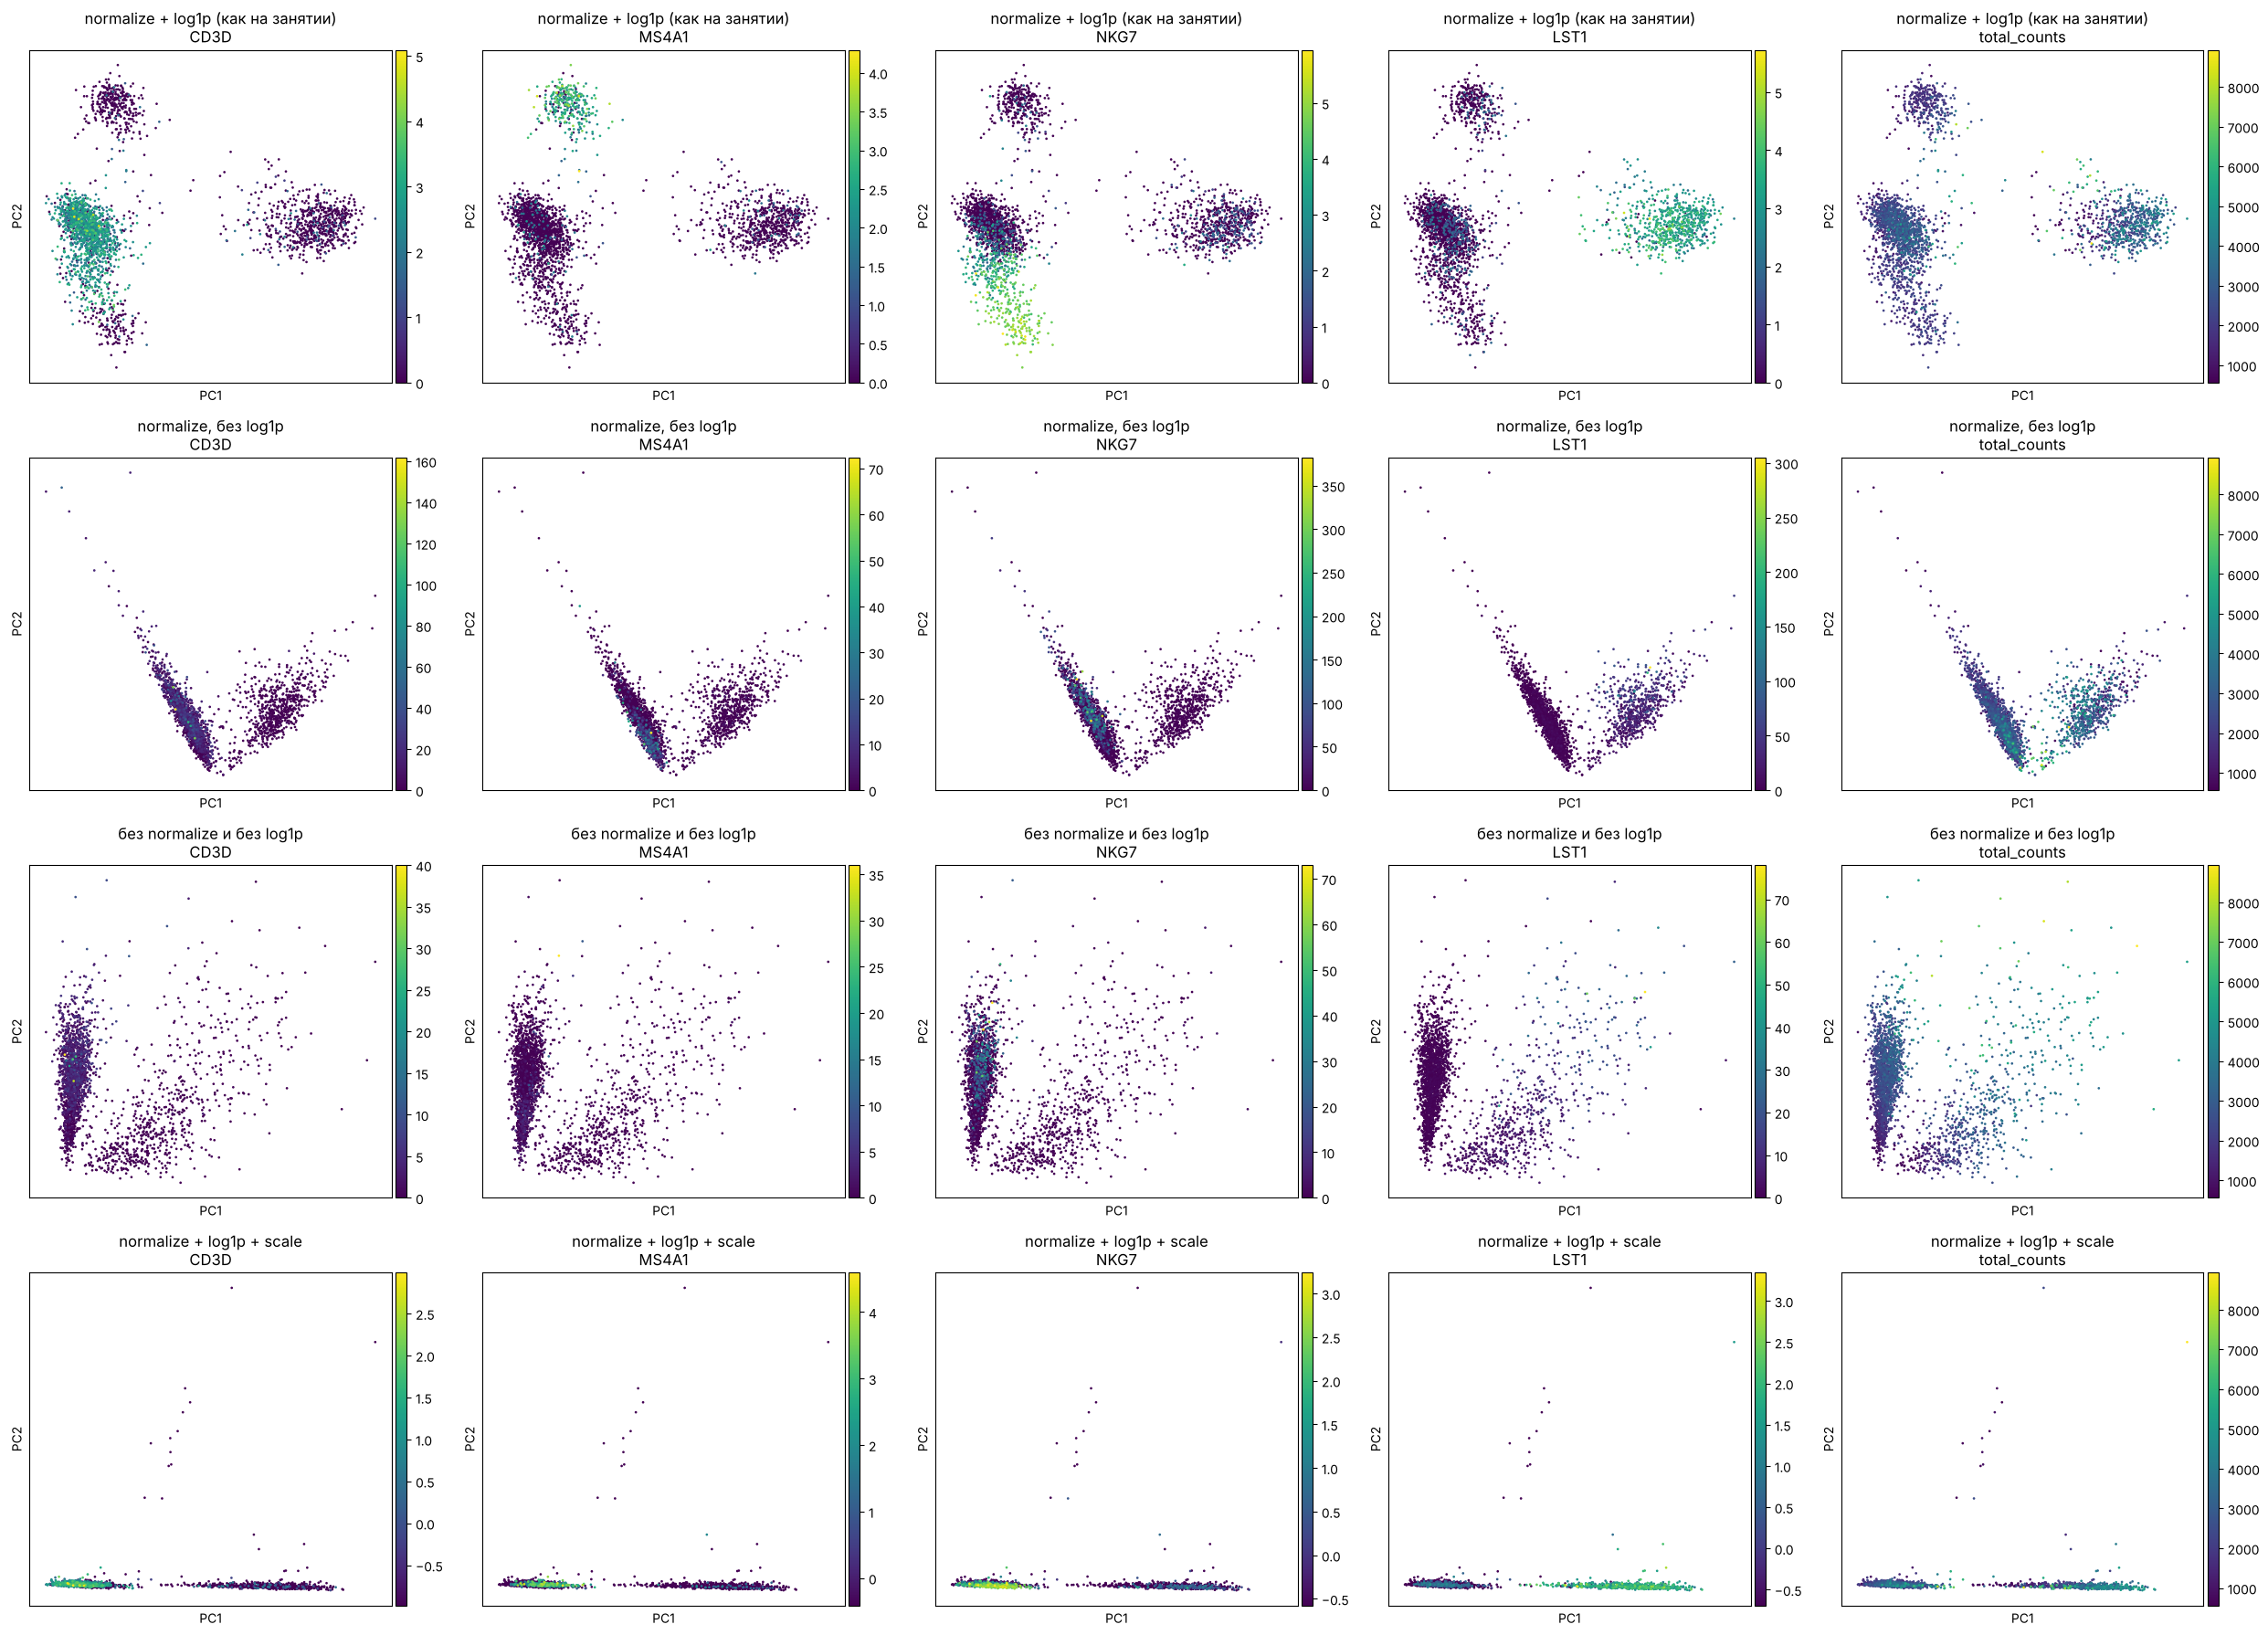

In [46]:
variants = {
    "normalize + log1p (как на занятии)": run_pipeline(adata_raw),
    "normalize, без log1p":              run_pipeline(adata_raw, log=False),
    "без normalize и без log1p":         run_pipeline(adata_raw, normalize=False, log=False),
    "normalize + log1p + scale":         run_pipeline(adata_raw, scale=True),
}

colors = MARKERS + ["total_counts"]
fig, axes = plt.subplots(4, 5, figsize=(25, 18))
for row, (name, ad) in zip(axes, variants.items()):
    for ax, c in zip(row, colors):
        sc.pl.pca(ad, color=c, ax=ax, show=False, size=15, title=f"{name}\n{c}")
plt.tight_layout(); plt.show()

In [47]:
# Доля дисперсии первых PC и связь PC1/PC2 с глубиной секвенирования
tab = pd.DataFrame({name: {
        "var PC1": ad.uns["pca"]["variance_ratio"][0],
        "var PC2": ad.uns["pca"]["variance_ratio"][1],
        "var PC1-10": ad.uns["pca"]["variance_ratio"][:10].sum(),
        "rho(PC1, total_counts)": pc_qc_corr(ad, ["total_counts"]).loc["total_counts", "PC1"],
        "rho(PC2, total_counts)": pc_qc_corr(ad, ["total_counts"]).loc["total_counts", "PC2"],
    } for name, ad in variants.items()})
tab.round(3)

,normalize + log1p (как на занятии),"normalize, без log1p",без normalize и без log1p,normalize + log1p + scale
var PC1,0.100,0.394,0.441,0.025
var PC2,0.033,0.109,0.143,0.014
var PC1-10,0.197,0.756,0.821,0.078
"rho(PC1, total_counts)",0.240,0.270,0.490,0.290
"rho(PC2, total_counts)",-0.070,-0.210,0.510,-0.250


In [48]:
# Какие гены доминируют в PC1 без логарифмирования
for name in ["normalize, без log1p", "без normalize и без log1p"]:
    ad = variants[name]
    l = pd.Series(ad.varm["PCs"][:, 0], index=ad.var_names)
    print(f"{name}: топ-5 |loading| PC1 →", list(l.abs().nlargest(5).index))

# Что формирует PC2 после scale
ad = variants["normalize + log1p + scale"]
l2 = pd.Series(ad.varm["PCs"][:, 1], index=ad.var_names)
print("scale: топ-8 |loading| PC2 →", list(l2.abs().nlargest(8).index))

normalize, без log1p: топ-5 |loading| PC1 → ['FTL', 'MALAT1', 'FTH1', 'LYZ', 'S100A9']
без normalize и без log1p: топ-5 |loading| PC1 → ['FTL', 'FTH1', 'TMSB4X', 'LYZ', 'ACTB']
scale: топ-8 |loading| PC2 → ['PTCRA', 'GP9', 'SDPR', 'GNG11', 'PF4', 'TMEM40', 'ITGA2B', 'AP001189.4']


### Выводы

- **Без log1p** (только normalize) PCA вырождается в «галочку» из двух лучей. PC1 объясняет 39 % дисперсии, а главные гены PC1 — `FTL`, `MALAT1`, `FTH1`, `LYZ`, `S100A9`, то есть просто самые высоко экспрессированные гены: без логарифма дисперсия растёт со средним, и они доминируют. Маркеры B, T и NK почти не разделяются.
- **Без normalize и без log1p** картина ещё хуже: облако растянуто вдоль глубины секвенирования. Связь с `total_counts` максимальна (ρ = 0.49 для PC1 и 0.51 для PC2), то есть главные компоненты частично описывают число UMI в клетке, а не тип клетки.
- **Что влияет сильнее.** Сильнее влияет **логарифмирование**: убрав только log1p, мы теряем почти всю структуру. Отказ ещё и от нормализации добавляет зависимость от глубины, но основная деградация уже произошла.
- **scale** (без `max_value`) заметно не помог: PC1 по-прежнему отделяет моноциты, а **PC2 захватили ~10–15 тромбоцитов** (`PF4`, `GP9`, `ITGA2B`, `GNG11`…). После стандартизации редкий ген, который экспрессирован в нескольких клетках, получает огромные z-score и такой же вес, как частые гены. Доля дисперсии первых PC падает (PC1 = 2.5 %), потому что все 2000 генов теперь вносят одинаковую дисперсию. На практике scale используют с обрезкой, `sc.pp.scale(adata, max_value=10)`, и тогда PC2 снова определяется NK-генами.
- **Что даёт каждая процедура:**
  - *нормализация* убирает различия в глубине секвенирования между клетками;
  - *log1p* стабилизирует дисперсию и сжимает «громкие» гены, чтобы PCA (метод, чувствительный к масштабу) не сводился к нескольким генам;
  - *стандартизация* уравнивает вклад генов.
- **Все ли шаги нужны перед PCA.** Нормализация и логарифмирование нужны обязательно. Scale — по желанию: он полезен, чтобы слабо экспрессированные маркеры участвовали в PCA, но усиливает шум и редкие гены, поэтому без обрезки его применять не стоит.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

### Решение

Списки генов фаз S и G2/M — стандартные списки Tirosh et al., 2016 (`cc.genes` из Seurat). Оценки считаются на лог-нормализованной матрице `adata.X`.

Найдено генов: S = 36 | G2M = 44


,count
phase,
G1,1685
S,866
G2M,87


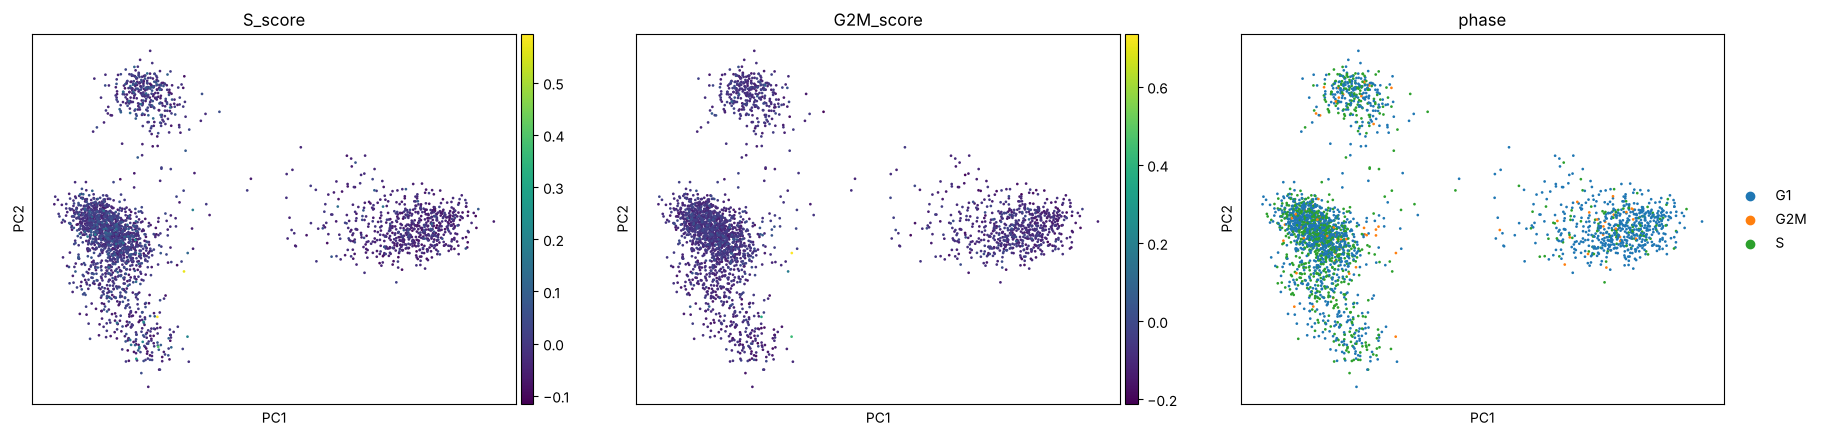

In [49]:
s_genes = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7",
           "DTL", "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN", "WDR76",
           "SLBP", "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45", "CDC6", "EXO1",
           "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B", "BRIP1", "E2F8"]
g2m_genes = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2", "CKS1B",
             "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2", "AURKB", "BUB1",
             "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1", "CDC20", "TTK", "CDC25C",
             "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2", "KIF23", "HMMR", "AURKA",
             "PSRC1", "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA"]

s_genes = [g for g in s_genes if g in adata.var_names]
g2m_genes = [g for g in g2m_genes if g in adata.var_names]
print("Найдено генов: S =", len(s_genes), "| G2M =", len(g2m_genes))

sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes, random_state=0)
display(adata.obs["phase"].value_counts().to_frame())

sc.pl.pca(adata, color=["S_score", "G2M_score", "phase"], ncols=3, size=15)

,PC1,PC2
S_score,-0.23,-0.01
G2M_score,-0.05,0.03


Клеток с S_score или G2M_score > 0.3: 5


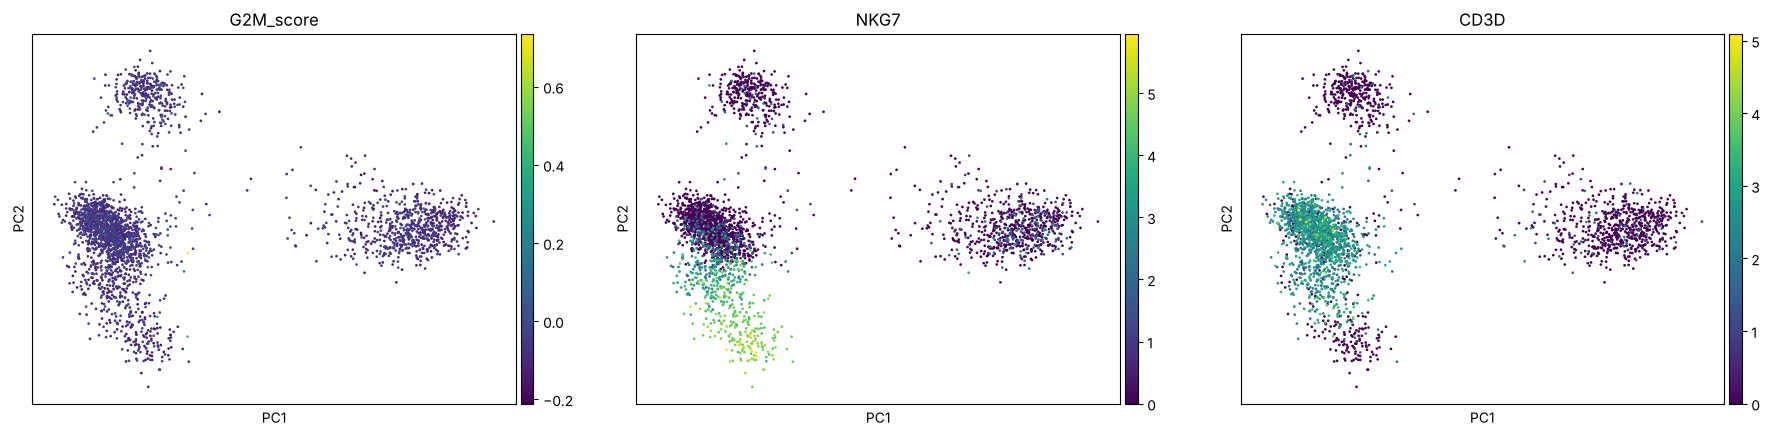

In [50]:
# Связь оценок клеточного цикла с PC1/PC2
display(pc_qc_corr(adata, ["S_score", "G2M_score"]))

# Где находятся клетки с самой высокой G2M/S-активностью
cycling = adata.obs[["S_score", "G2M_score"]].max(axis=1) > 0.3
print("Клеток с S_score или G2M_score > 0.3:", cycling.sum())
sc.pl.pca(adata, color=["G2M_score", "NKG7", "CD3D"], ncols=3, size=15)

### Выводы

- **Разделения по фазам нет.** Формально клетки распределились так: G1 — 1685, S — 866, G2M — 87. Но S_score и G2M_score почти у всех клеток близки к нулю, и метки `S` / `G2M` разбросаны по всему PCA вперемешку с G1. Реально пролиферирующих клеток (score > 0.3) всего **5**. `score_genes_cell_cycle` присваивает фазу по знаку оценки, поэтому при оценке ≈ 0 метка определяется шумом.
- **Связи с PC1/PC2 практически нет:** S_score ρ = −0.23 с PC1 (слабо), G2M_score |ρ| ≤ 0.05. Слабый сдвиг S_score в сторону лимфоцитов скорее связан с тем, что у лимфоцитов в целом детектируется другой набор генов, чем с реальным делением. Клеточный цикл не определяет главные компоненты. Это ожидаемо: в периферической крови здорового донора зрелые клетки почти не делятся.
- **Почему клетки одного типа различаются по генам цикла.** Даже в одной популяции часть клеток может быть активирована и пролиферировать (например, NK- или T-клетки при иммунном ответе), а остальные покоятся. Кроме того, гены цикла детектируются редко, и в отдельной клетке их оценка сильно зашумлена из-за малого числа UMI.